In [665]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("usf.csv")

df.shape

#44 cols
# n = 107 samples

(107, 44)

In [666]:
df.isna().sum()

Timestamp                                                                       0
Are you 21 years of age or older?                                               0
Have you had a completed night out within the past 30 days?                     0
Are you currently under the influence taking this survey                        0
Please enter your age                                                           2
Which best describes your gender?                                               2
What is your height?                                                           16
Which best describes your current education status?                             2
How financially comfortable do you currently feel?                              2
Which SF Neighborhood do you live in?                                           2
Where did you receive this survey?                                              2
What day of the week was this night out?                                        2
How planned was 

<Axes: >

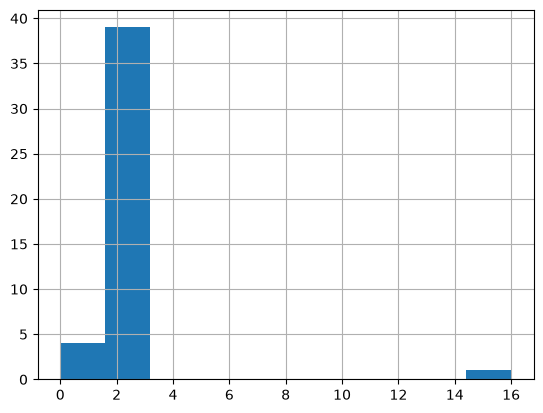

In [667]:
df.isna().sum().hist()

# Most columns with missing values have only 2 missing, but heights have 16. 
# We can infer that people may not like telling us their heights

In [668]:
#how much would we be losing if we dropped all missing rows

len(df) - len(df.dropna(how='any')) # we cannot drop all of them, majority of rows are dropped

16

In [669]:
df = df.rename(columns = {'Are you 21 years of age or older?': '21?'})

#scripting
#col 1

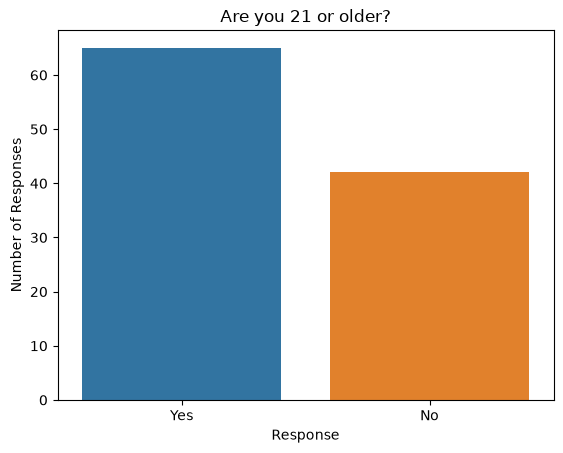

21?
Yes    65
No     42
Name: count, dtype: int64


In [670]:
sns.countplot(data=df, x='21?', hue = '21?', legend = False)
plt.title("Are you 21 or older?")
plt.xlabel("Response")
plt.ylabel("Number of Responses")
plt.show()
plt.show()
print(df['21?'].value_counts())

In [671]:
df.Timestamp.nunique

<bound method IndexOpsMixin.nunique of 0      11/12/2026 14:03:21
1      11/12/2026 14:03:24
2      11/12/2026 14:08:12
3      11/12/2026 14:09:20
4      11/12/2026 14:09:21
              ...         
102    11/17/2026 16:53:12
103    11/17/2026 20:37:14
104    11/18/2026 14:11:19
105    11/18/2026 18:42:13
106     11/19/2026 0:56:32
Name: Timestamp, Length: 107, dtype: object>

Drop time stamp: Difficult for get_dummies conversion and we should treat each response as iid distributed, so we're going to treat time as unimportant.

In [672]:
df.drop(columns='Timestamp', inplace= True)
#scripting
df.nunique()
# col 2
#column successfully dropped

21?                                                                             2
Have you had a completed night out within the past 30 days?                     2
Are you currently under the influence taking this survey                        2
Please enter your age                                                          16
Which best describes your gender?                                               5
What is your height?                                                           56
Which best describes your current education status?                             5
How financially comfortable do you currently feel?                              5
Which SF Neighborhood do you live in?                                          58
Where did you receive this survey?                                             19
What day of the week was this night out?                                        7
How planned was this night out?                                                 4
At approximately

In [673]:
# col 3

df['Have you had a completed night out within the past 30 days?'].value_counts()

#scripting
df = df.rename(columns= {'Have you had a completed night out within the past 30 days?' : 'night_out_last30'})


#rename ran successfully

In [674]:
df.head()

df['Are you currently under the influence taking this survey'].value_counts()

# ~ 10% of the data are from people under the influence
#scripting
df = df.rename(columns = {'Are you currently under the influence taking this survey': 'under influence'})

# successfully renamed

In [675]:
df.head(1)

,21?,night_out_last30,under influence,Please enter your age,Which best describes your gender?,What is your height?,Which best describes your current education status?,How financially comfortable do you currently feel?,Which SF Neighborhood do you live in?,Where did you receive this survey?,...,Would a pregame be a necessity for your night out?,How many people is ideal for the perfect night out?,What type of people would be ideal?,Approximately how much money do you feel is needed for the night out (USD)?,What would be the best way to get around during your night out?,Would you need to consume alcohol (in any capacity)?,Would you need to consume any other substances other than alcohol?,Does your perfect night end with you being...,How many locations would you like to visit?,"At the end of the night, would you want to have something to eat?"
0,Yes,No,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Average age: 22.67
Standard Deviation: 5.15
Max Age: 49.0
Min Age: 18.0


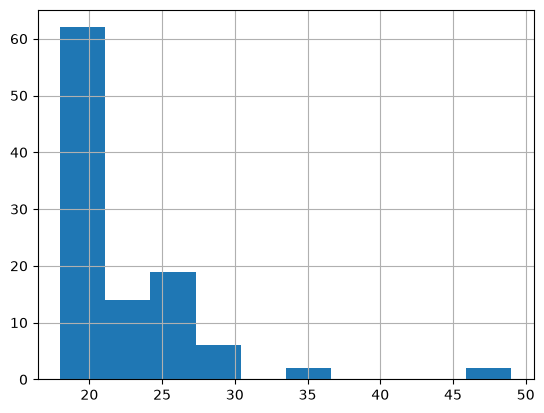

In [676]:
df['Please enter your age'].hist()
print(f'Average age: {round(df['Please enter your age'].mean(),2)}')
print(f'Standard Deviation: {round(df['Please enter your age'].std(),2)}')
print(f'Max Age: {df['Please enter your age'].max()}')
print(f'Min Age: {df['Please enter your age'].min()}')

In [680]:
df['age'].describe()

count    105.000000
mean      22.666667
std        5.149060
min       18.000000
25%       20.000000
50%       21.000000
75%       25.000000
max       49.000000
Name: age, dtype: float64

In [678]:
print(df['Please enter your age'].value_counts())

Please enter your age
21.0    20
20.0    16
19.0    16
18.0    10
27.0     9
22.0     8
26.0     5
25.0     5
23.0     4
29.0     3
35.0     2
30.0     2
24.0     2
28.0     1
48.0     1
49.0     1
Name: count, dtype: int64


In [679]:
df = df.rename(columns= {"Please enter your age": 'age' })
df.head(1)
#scripting

,21?,night_out_last30,under influence,age,Which best describes your gender?,What is your height?,Which best describes your current education status?,How financially comfortable do you currently feel?,Which SF Neighborhood do you live in?,Where did you receive this survey?,...,Would a pregame be a necessity for your night out?,How many people is ideal for the perfect night out?,What type of people would be ideal?,Approximately how much money do you feel is needed for the night out (USD)?,What would be the best way to get around during your night out?,Would you need to consume alcohol (in any capacity)?,Would you need to consume any other substances other than alcohol?,Does your perfect night end with you being...,How many locations would you like to visit?,"At the end of the night, would you want to have something to eat?"
0,Yes,No,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [681]:
df['Which best describes your gender?'].value_counts()

# 5 unqiue values. Probably drop it, as get dummies step will create new column for 
# the 2 people: trans man and gender fluid.


#scripting
df = df.rename(columns = {'Which best describes your gender?' : 'gender'})

In [682]:
df['gender'].value_counts()

gender
Female         50
Male           47
Non-Binary      6
Trans man       1
genderfluid     1
Name: count, dtype: int64

In [683]:
# scripting

#df = df.query('gender == Male or gender == Female or gender = Non-Binary')
df = df.query("gender == 'Male' or gender == 'Female' or gender == 'Non-Binary'")
df.gender.value_counts()

#success

gender
Female        50
Male          47
Non-Binary     6
Name: count, dtype: int64

In [684]:
df.head(5) # successful rename

,21?,night_out_last30,under influence,age,gender,What is your height?,Which best describes your current education status?,How financially comfortable do you currently feel?,Which SF Neighborhood do you live in?,Where did you receive this survey?,...,Would a pregame be a necessity for your night out?,How many people is ideal for the perfect night out?,What type of people would be ideal?,Approximately how much money do you feel is needed for the night out (USD)?,What would be the best way to get around during your night out?,Would you need to consume alcohol (in any capacity)?,Would you need to consume any other substances other than alcohol?,Does your perfect night end with you being...,How many locations would you like to visit?,"At the end of the night, would you want to have something to eat?"
2,Yes,Yes,No,21.0,Male,5’11,Currently pursuing an associate or bachelor’s ...,4.0,Balboa,USF / University,...,No,0,Alone,50.0,Ride-share / Taxi,No,No,Tipsy,2,"Yes, Something at home (Something you'd make)"
3,Yes,Yes,No,21.0,Male,6’0,Currently pursuing an associate or bachelor’s ...,3.0,Sunset,USF / University,...,Yes,6,"Friends, Family",40.0,Walking,Yes,No,Tipsy,3,"Yes, Food delivery (e.g. Doordash)"
4,Yes,Yes,No,22.0,Female,NaN,Currently pursuing an associate or bachelor’s ...,2.0,Anza Vista,USF / University,...,No,4,"Friends, Family",15.0,Riding with someone else,No,No,Sober,2,"Yes, Something at home (Something you'd make)"
5,Yes,Yes,No,21.0,Male,6’4,Currently pursuing an associate or bachelor’s ...,5.0,Uni dorm,USF / University,...,No,2,Friends,200.0,Riding with someone else,No,No,Sober,5+,"Yes, Late night restaurant"
6,Yes,No,No,22.0,Female,164cm,Currently pursuing an associate or bachelor’s ...,4.0,lone mountain,USF / University,...,No,2,Friends,100.0,Driving myself,Yes,No,Tipsy,2,"Yes, Late night restaurant"


In [685]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
What is your height?                                                           54
Which best describes your current education status?                             5
How financially comfortable do you currently feel?                              5
Which SF Neighborhood do you live in?                                          58
Where did you receive this survey?                                             19
What day of the week was this night out?                                        7
How planned was this night out?                                                 4
At approximately

In [686]:
df = df.rename(columns = {"What is your height?" : "height"})
# scripting


In [687]:
df['height'].value_counts()

height
5’6                                             7
5'10                                            5
5’3                                             4
5’4”                                            4
5’5                                             4
5'2                                             3
5’9                                             3
5’8                                             3
5’11                                            2
5’9”                                            2
5'5                                             2
6’0                                             2
5'3                                             2
5’7                                             2
5’4                                             2
5'6"                                            2
5’2                                             2
5’5”                                            2
6 ft                                            1
5'6                                        

In [688]:
# Ai generated function to convert/clean heights responses:
import pandas as pd
import numpy as np
import re

def clean_height(value):
    if pd.isna(value):
        return np.nan

    # Standardize curly quotation marks
    s = str(value).lower().strip()
    s = s.replace("’", "'").replace("‘", "'")
    s = s.replace("”", '"').replace("“", '"')

    # Centimeters: 164cm
    match = re.fullmatch(r"(\d+(?:\.\d+)?)\s*cm", s)
    if match:
        return float(match.group(1))

    # Feet and inches: 5'6, 5'10", 6' 1"
    match = re.fullmatch(r"(\d+)\s*'\s*(\d{1,2})?\s*(?:\"|in)?", s)
    if match:
        feet = int(match.group(1))
        inches = int(match.group(2) or 0)

        if inches < 12:
            return round(feet * 30.48 + inches * 2.54, 2)

    # Written format: 5ft 6in, 6 ft, 6 feet
    match = re.fullmatch(
        r"(\d+)\s*(?:ft|feet)\s*(\d{1,2})?\s*(?:in|inches)?", s
    )
    if match:
        feet = int(match.group(1))
        inches = int(match.group(2) or 0)

        if inches < 12:
            return round(feet * 30.48 + inches * 2.54, 2)

    # Hyphenated: 5-10
    match = re.fullmatch(r"(\d+)-(\d{1,2})", s)
    if match:
        feet = int(match.group(1))
        inches = int(match.group(2))

        if inches < 12:
            return round(feet * 30.48 + inches * 2.54, 2)

    # Unusual: 5 8'
    match = re.fullmatch(r"(\d+)\s+(\d{1,2})'", s)
    if match:
        feet = int(match.group(1))
        inches = int(match.group(2))

        if inches < 12:
            return round(feet * 30.48 + inches * 2.54, 2)

    # Anything ambiguous or invalid
    return np.nan

In [689]:
df["height_cm"] = df["height"].apply(clean_height)
#script
df['height_cm']

2      180.34
3      182.88
4         NaN
5      193.04
6      164.00
        ...  
102    162.56
103    160.02
104    167.64
105       NaN
106    170.18
Name: height_cm, Length: 103, dtype: float64

<Axes: >

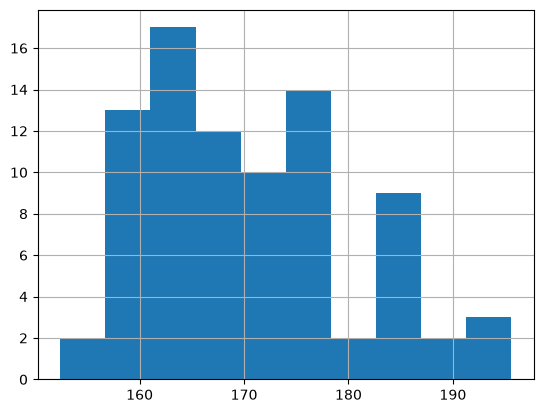

In [690]:
df['height_cm'].hist()

In [691]:
df['height_cm'].describe() # large variance in height

count     84.000000
mean     170.590238
std        9.856042
min      152.400000
25%      162.560000
50%      167.640000
75%      177.800000
max      195.580000
Name: height_cm, dtype: float64

In [692]:
df['height_cm'].value_counts() # perfect

height_cm
167.64    12
165.10     8
177.80     8
162.56     8
157.48     7
182.88     7
160.02     6
175.26     6
172.72     5
170.18     5
180.34     2
195.58     2
185.42     2
190.50     1
154.94     1
152.40     1
164.00     1
193.04     1
187.96     1
Name: count, dtype: int64

In [693]:
df[['height', 'height_cm']].value_counts()

height    height_cm
5’6       167.64       7
5'10      177.80       5
5’4”      162.56       4
5’5       165.10       4
5’3       160.02       4
5'2       157.48       3
5’8       172.72       3
5’9       175.26       3
5’2       157.48       2
6’0       182.88       2
5’5”      165.10       2
5'5       165.10       2
5'6"      167.64       2
5’4       162.56       2
5’7       170.18       2
5'3       160.02       2
5’9”      175.26       2
5’11      180.34       2
6’4       193.04       1
6’1”      185.42       1
5’7”      170.18       1
6 ft      182.88       1
6 feet    182.88       1
6'        182.88       1
6'0       182.88       1
6'2       187.96       1
6'3"      190.50       1
6'5       195.58       1
6ft       182.88       1
6' 1"     185.42       1
164cm     164.00       1
5’6”      167.64       1
5 8'      172.72       1
5'1       154.94       1
5'10"     177.80       1
5'4       162.56       1
5'4"      162.56       1
5'6       167.64       1
5'7       170.18       1
5'7" 

In [694]:
df = df.drop(columns='height')

In [695]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
Which best describes your current education status?                             5
How financially comfortable do you currently feel?                              5
Which SF Neighborhood do you live in?                                          58
Where did you receive this survey?                                             19
What day of the week was this night out?                                        7
How planned was this night out?                                                 4
At approximately what time did your night out begin?                           30
Where did you sp

In [696]:
df.isna().sum()

21?                                                                             0
night_out_last30                                                                0
under influence                                                                 0
age                                                                             0
gender                                                                          0
Which best describes your current education status?                             0
How financially comfortable do you currently feel?                              0
Which SF Neighborhood do you live in?                                           0
Where did you receive this survey?                                              0
What day of the week was this night out?                                        0
How planned was this night out?                                                 0
At approximately what time did your night out begin?                            0
Where did you sp

In [697]:
df.shape

(103, 43)

In [698]:
df['Which best describes your current education status?'].value_counts()

Which best describes your current education status?
Currently pursuing an associate or bachelor’s degree                   69
Completed an associate or bachelor’s degree, not currently enrolled    16
Completed a graduate or professional degree, not currently enrolled     8
Currently pursuing a graduate or professional degree                    6
High school graduate or equivalent, not enrolled in college             4
Name: count, dtype: int64

In [699]:
df = df.rename(columns={'Which best describes your current education status?': 'education_level'})


#scripting

# Ordinal ordering:

List:

2: Currently pursuing an associate or bachelor’s degree                   
3: Completed an associate or bachelor’s degree, not currently enrolled    
5: Completed a graduate or professional degree, not currently enrolled     
4: Currently pursuing a graduate or professional degree                    
1: High school graduate or equivalent, not enrolled in college    

1 --> 5 : as number increases, education level increases WRT ordinal ordering

1: High school

2: Currently pursuing associate/bachelors

3: Completed associate/bachelors

4: Currenttly pursuing graduate degree

5: Completed Graduate degree

In [700]:
education_map = {
    'High school graduate or equivalent, not enrolled in college' : 1,
    'Currently pursuing an associate or bachelor’s degree' : 2,
    'Completed an associate or bachelor’s degree, not currently enrolled' : 3,
    'Currently pursuing a graduate or professional degree' : 4,
    'Completed a graduate or professional degree, not currently enrolled': 5
}

In [701]:
df['education_ranking'] = df['education_level'].map(education_map)

#script

In [702]:
df['education_ranking'].value_counts()

education_ranking
2    69
3    16
5     8
4     6
1     4
Name: count, dtype: int64

In [703]:
df['education_level'].value_counts()

education_level
Currently pursuing an associate or bachelor’s degree                   69
Completed an associate or bachelor’s degree, not currently enrolled    16
Completed a graduate or professional degree, not currently enrolled     8
Currently pursuing a graduate or professional degree                    6
High school graduate or equivalent, not enrolled in college             4
Name: count, dtype: int64

In [704]:
df = df.drop(columns='education_level')
df.value_counts()

21?  night_out_last30  under influence  age   gender  How financially comfortable do you currently feel?  Which SF Neighborhood do you live in?  Where did you receive this survey?  What day of the week was this night out?  How planned was this night out?  At approximately what time did your night out begin?  Where did you spend most of the night?  Did you pregame?  How many people were in your group, including yourself?  Who did you primarily spend the night with?  What was your primary mode of transportation?  Approximately how many hours did your night out last?  At approximately what time did your night end?  Approximately how much money did you personally spend (USD)?  Did you consume any alcohol during this night out?  Did you consume substances other than alcohol?  Did you end the night...  How many different venues or locations did you visit?  At the end of the night, did you have something to eat?  Overall, how enjoyable was this night out?  What day of the week would this nigh

In [705]:
df['education_ranking'].value_counts()

education_ranking
2    69
3    16
5     8
4     6
1     4
Name: count, dtype: int64

count    103.000000
mean       2.466019
std        0.958098
min        1.000000
25%        2.000000
50%        2.000000
75%        3.000000
max        5.000000
Name: education_ranking, dtype: float64

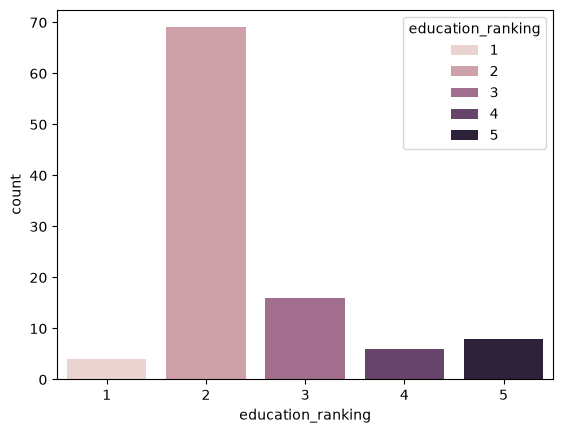

In [706]:
sns.countplot(data = df, x = 'education_ranking', hue = 'education_ranking')

# most people from this sample are pursuing bachelors/associates,
# which makes sense because everyone is 18+ and avg age = 22
df['education_ranking'].describe()
# left skewed

In [707]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
How financially comfortable do you currently feel?                              5
Which SF Neighborhood do you live in?                                          58
Where did you receive this survey?                                             19
What day of the week was this night out?                                        7
How planned was this night out?                                                 4
At approximately what time did your night out begin?                           30
Where did you spend most of the night?                                         29
Did you pregame?

In [708]:
df['How financially comfortable do you currently feel?'].value_counts().sort_values()

How financially comfortable do you currently feel?
1.0     5
5.0    11
2.0    18
4.0    27
3.0    42
Name: count, dtype: int64

In [709]:
df = df.rename(columns = {'How financially comfortable do you currently feel?':
                     'finance'})# worked

#script
#rename succesfful

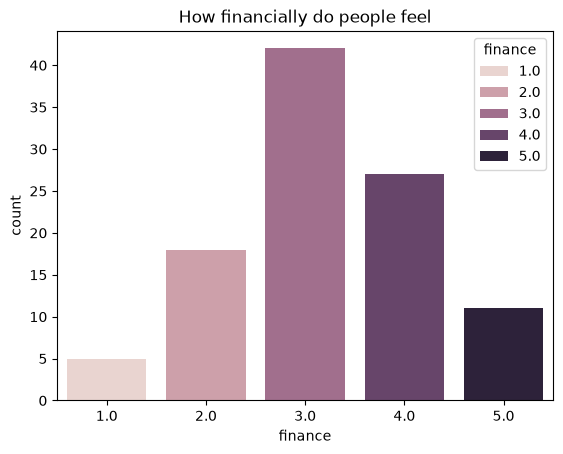

count    103.000000
mean       3.203883
std        1.013238
min        1.000000
25%        3.000000
50%        3.000000
75%        4.000000
max        5.000000
Name: finance, dtype: float64

In [710]:
sns.countplot(data=df, x = df['finance'], hue = 'finance')
plt.title("How financially do people feel")
plt.show()
df['finance'].describe() # right skewed

In [711]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
Which SF Neighborhood do you live in?                                          58
Where did you receive this survey?                                             19
What day of the week was this night out?                                        7
How planned was this night out?                                                 4
At approximately what time did your night out begin?                           30
Where did you spend most of the night?                                         29
Did you pregame?

In [712]:
df = df.rename(columns={'Which SF Neighborhood do you live in?': 'neighborhood'})

In [713]:
df.neighborhood.value_counts()

neighborhood
Other                                                                                    25
Inner Richmond                                                                            7
Lone Mountain                                                                             6
Sunset                                                                                    5
other                                                                                     4
Ingleside                                                                                 3
Inner Richmond                                                                            2
Sunset                                                                                    1
Richmond                                                                                  1
Bayview                                                                                   1
Park Merced                                                        

In [714]:
#AI generated mapping:

import pandas as pd
import re

def clean_neighborhood(value):
    if pd.isna(value):
        return "Unknown"

    # Standardize text
    s = re.sub(r"\s+", " ", str(value).strip().lower())

    # Missing or unspecified locations
    if s == "other":
        return "Unknown"

    # Clearly outside San Francisco
    outside_sf = {
        "sa jose", "daly city", "south san francisco",
        "other! la babey!!!", "other - (carson)"
    }
    if s in outside_sf:
        return "Outside SF"

    # Explicit USF campus housing responses
    campus = {
        "on usf campus",
        "i live on campus.",
        "nopa (on campus)",
        "on campus at usf",
        "wherever usf is",
        "gillson hall",
        "richmond (live on campus)",
        "usf campus/laural heights",
        "i live at the university of san francisco - which is considered to be inner richmond.",
        "uni dorm",
        "on campus",
        "lone mountain north residence hall",
        "fulton street, usf",
        "on usf campus"
    }
    if s in campus:
        return "USF Campus"

    # Neighborhood aliases and spelling variations
    mapping = {
        "inner richmond": "Richmond",
        "middle richmond": "Richmond",
        "richmond": "Richmond",
        "richmond district": "Richmond",

        "sunset": "Sunset",
        "outer sunset": "Sunset",
        "outer sunset district": "Sunset",

        "lone mountain": "Lone Mountain",

        "mission": "Mission",
        "mission district": "Mission",
        "misson bay": "Mission Bay",

        "lower pac": "Lower Pacific Heights",
        "lower pac heights": "Lower Pacific Heights",
        "lowe pacific heights": "Lower Pacific Heights",

        "park merced": "Parkmerced",
        "balboa": "Balboa",
        "soma": "SoMa"
    }

    # Apply mapping; preserve any other named location
    return mapping.get(s, str(value).strip().title())


# Create cleaned column
df["neighborhood_clean"] = df["neighborhood"].apply(clean_neighborhood)

# Check results
print(df["neighborhood_clean"].value_counts())

neighborhood_clean
Unknown                  31
USF Campus               14
Richmond                 12
Lone Mountain             8
Sunset                    8
Outside SF                5
Lower Pacific Heights     3
Ingleside                 3
Mission                   2
Mission Bay               1
Parkmerced                1
Japantown                 1
Balboa                    1
Miraloma                  1
Portola                   1
Panhandle                 1
Bayview                   1
Irving                    1
Fillmore                  1
Forest Hill               1
Excelsior                 1
Golden Gate               1
SoMa                      1
Presidio                  1
Anza Vista                1
Laurel Heights            1
Name: count, dtype: int64


In [715]:
df = df.drop(columns="neighborhood")
#script
df = df.rename(columns= {"neighborhood_clean": "neighborhood"})

In [716]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
Where did you receive this survey?                                             19
What day of the week was this night out?                                        7
How planned was this night out?                                                 4
At approximately what time did your night out begin?                           30
Where did you spend most of the night?                                         29
Did you pregame?                                                                2
How many people 

In [717]:
df['Where did you receive this survey?'].value_counts()

Where did you receive this survey?
USF / University                          59
Social Media                              16
At a bar or nightlife venue                8
Friend                                     4
friend                                     2
Friend/former co worker                    1
Personal Reference                         1
From Lucas                                 1
Lucas ❤️                                   1
USF student                                1
Lucas  sent it to me                       1
Friend from USF                            1
work                                       1
coworker who is friend of survey giver     1
Cecilia                                    1
Through a link from a friend               1
Referral                                   1
Peter from canvas                          1
Calculus II Professor                      1
Name: count, dtype: int64

In [718]:
import pandas as pd

def clean_source(value):

    if pd.isna(value):
        return "Unknown"

    s = str(value).strip().lower()

    # University-related
    university = {
        "usf / university",
        "usf student",
        "peter from canvas",
        "calculus ii professor"
    }

    # Personal referrals
    referral = {
        "friend",
        "friend/former co worker",
        "personal reference",
        "from lucas",
        "lucas ❤️",
        "lucas sent it to me",
        "friend from usf",
        "coworker who is friend of survey giver",
        "cecilia",
        "through a link from a friend",
        "referral"
    }

    if s in university:
        return "University"

    elif s == "social media":
        return "Social Media"

    elif s == "at a bar or nightlife venue":
        return "Bar / Nightlife"

    elif s in referral:
        return "Personal Referral"

    elif s == "work":
        return "Work"

    else:
        return "Unknown"


# Apply mapping
df["survey_source_clean"] = df[
    "Where did you receive this survey?"
].apply(clean_source)

# Verify categories
print(df["survey_source_clean"].value_counts())

#script

survey_source_clean
University           62
Social Media         16
Personal Referral    15
Bar / Nightlife       8
Unknown               1
Work                  1
Name: count, dtype: int64


In [719]:
print(df["Where did you receive this survey?"].nunique())

19


In [720]:
print(df["survey_source_clean"].nunique())

6


In [721]:
df["survey_source_clean"].count().sum()

np.int64(103)

In [722]:
df["Where did you receive this survey?"].count().sum()

np.int64(103)

In [723]:
df = df.drop(columns= "Where did you receive this survey?")
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
What day of the week was this night out?                                        7
How planned was this night out?                                                 4
At approximately what time did your night out begin?                           30
Where did you spend most of the night?                                         29
Did you pregame?                                                                2
How many people were in your group, including yourself?                         8
Who did you prim

What day of the week was this night out?
Saturday     42
Friday       37
Thursday      9
Wednesday     6
Tuesday       5
Monday        3
Sunday        1
Name: count, dtype: int64


<Axes: >

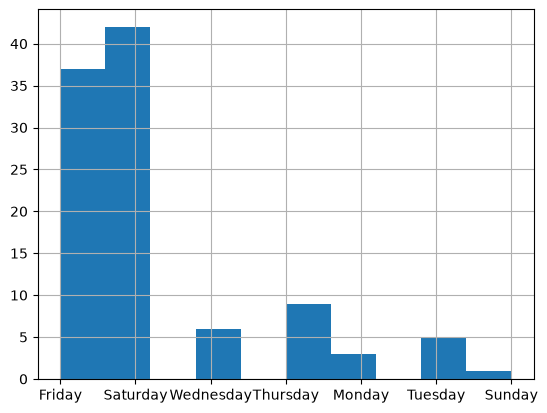

In [724]:
print(df['What day of the week was this night out?'].value_counts())
df['What day of the week was this night out?'].hist()
#most people are on friday/saturday, makes sense

In [725]:
df = df.rename(columns={'What day of the week was this night out?'
                        : 'day_of_week'})

#script

df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
How planned was this night out?                                                 4
At approximately what time did your night out begin?                           30
Where did you spend most of the night?                                         29
Did you pregame?                                                                2
How many people were in your group, including yourself?                         8
Who did you prim

In [726]:
df['How planned was this night out?'].unique()

array(['Somewhat planned', 'Planned well in advance',
       'Somewhat spontaneous', 'Completely spontaneous'], dtype=object)

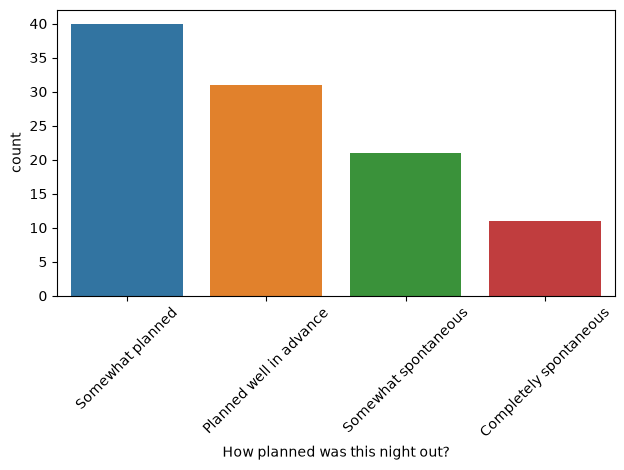

In [727]:
sns.countplot(data =df, x = "How planned was this night out?", hue = "How planned was this night out?")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [728]:
df = df.rename(columns= {'How planned was this night out?' : 'plan_rating'})

In [729]:
df['plan_rating'].unique()

array(['Somewhat planned', 'Planned well in advance',
       'Somewhat spontaneous', 'Completely spontaneous'], dtype=object)

Four options, ordinal:

1 -- > 4; as number inceases, it becomes more well planned

1. Completely spontaneous
2. Somewhat spontaneous
3. Somewhat planned
4. Planned well in advaced

surprisingly, most people at least somewhat plan it. 

In [730]:
planMap = {
    "Completely spontaneous": 1,
    "Somewhat spontaneous": 2,
    "Somewhat planned": 3,
    "Planned well in advance": 4
}

df["plan_rating"] = df["plan_rating"].map(planMap)

In [731]:
df.head()

,21?,night_out_last30,under influence,age,gender,finance,day_of_week,plan_rating,At approximately what time did your night out begin?,Where did you spend most of the night?,...,What would be the best way to get around during your night out?,Would you need to consume alcohol (in any capacity)?,Would you need to consume any other substances other than alcohol?,Does your perfect night end with you being...,How many locations would you like to visit?,"At the end of the night, would you want to have something to eat?",height_cm,education_ranking,neighborhood,survey_source_clean
2,Yes,Yes,No,21.0,Male,4.0,Friday,3,8:00:00 PM,Bar or pub,...,Ride-share / Taxi,No,No,Tipsy,2,"Yes, Something at home (Something you'd make)",180.34,2,Balboa,University
3,Yes,Yes,No,21.0,Male,3.0,Saturday,4,7:00:00 PM,Bar or pub,...,Walking,Yes,No,Tipsy,3,"Yes, Food delivery (e.g. Doordash)",182.88,2,Sunset,University
4,Yes,Yes,No,22.0,Female,2.0,Wednesday,4,5:00:00 PM,Restaurant,...,Riding with someone else,No,No,Sober,2,"Yes, Something at home (Something you'd make)",NaN,2,Anza Vista,University
5,Yes,Yes,No,21.0,Male,5.0,Saturday,2,12:00:00 PM,Cafe,...,Riding with someone else,No,No,Sober,5+,"Yes, Late night restaurant",193.04,2,USF Campus,University
6,Yes,No,No,22.0,Female,4.0,Friday,1,11:20:00 PM,Nightclub,...,Driving myself,Yes,No,Tipsy,2,"Yes, Late night restaurant",164.00,2,Lone Mountain,University


In [732]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
At approximately what time did your night out begin?                           30
Where did you spend most of the night?                                         29
Did you pregame?                                                                2
How many people were in your group, including yourself?                         8
Who did you prim

In [733]:
df['At approximately what time did your night out begin?'].value_counts()

At approximately what time did your night out begin?
9:00:00 PM     16
8:00:00 PM     15
10:00:00 PM    14
7:00:00 PM      7
6:00:00 PM      7
5:00:00 PM      6
6:30:00 PM      4
11:00:00 PM     3
8:30:00 PM      3
11:30:00 PM     3
1:00:00 AM      2
10:30:00 PM     2
4:00:00 PM      2
11:20:00 PM     2
12:00:00 PM     2
2:16:00 AM      1
8:00:00 AM      1
10:45:00 PM     1
3:30:00 PM      1
5:30:00 PM      1
12:00:00 AM     1
7:50:00 PM      1
2:30:00 PM      1
10:15:00 PM     1
6:18:00 PM      1
6:45:00 AM      1
9:45:00 PM      1
10:40:00 PM     1
9:30:00 PM      1
4:30:00 PM      1
Name: count, dtype: int64

In [734]:
df.rename(inplace=True, columns = {'At approximately what time did your night out begin?' : 'time_start'})

In [735]:
# Step 1: Convert text into datetime objects
times = pd.to_datetime(
    df["time_start"],
    format="%I:%M:%S %p",
    errors="coerce"
)

# Step 2: Convert to decimal hours
# Example: 9:30 PM → 21 + 30/60 = 21.5
df["start_hour"] = times.dt.hour + times.dt.minute / 60

# Step 3: Adjust times after midnight
# Example: 1 AM → 1 + 24 = 25
df["start_hour"] = df["start_hour"].where(
    df["start_hour"] >= 12,
    df["start_hour"] + 24
)

#script

# Inspect results
print(df[["time_start", "start_hour"]].head(10))

     time_start  start_hour
2    8:00:00 PM   20.000000
3    7:00:00 PM   19.000000
4    5:00:00 PM   17.000000
5   12:00:00 PM   12.000000
6   11:20:00 PM   23.333333
7    9:00:00 PM   21.000000
8    8:00:00 PM   20.000000
9   11:30:00 PM   23.500000
10  10:00:00 PM   22.000000
11  10:00:00 PM   22.000000


In [736]:
df["start_hour"] = df["start_hour"] % 24

In [737]:
test['time_start'].unique()

array(['8:00:00 PM', '7:00:00 PM', '5:00:00 PM', '12:00:00 PM',
       '11:20:00 PM', '9:00:00 PM', '11:30:00 PM', '10:00:00 PM',
       '9:30:00 PM', '1:00:00 AM', '10:40:00 PM', '11:00:00 PM',
       '9:45:00 PM', '4:00:00 PM', '6:00:00 PM', '7:50:00 PM',
       '6:45:00 AM', '6:30:00 PM', '6:18:00 PM', '10:15:00 PM',
       '2:30:00 PM', '5:30:00 PM', '12:00:00 AM', '2:16:00 AM',
       '8:00:00 AM', '3:30:00 PM', '10:30:00 PM', '10:45:00 PM',
       '8:30:00 PM', '4:30:00 PM'], dtype=object)

In [738]:
df['start_hour'].unique()

array([20.        , 19.        , 17.        , 12.        , 23.33333333,
       21.        , 23.5       , 22.        , 21.5       ,  1.        ,
       22.66666667, 23.        , 21.75      , 16.        , 18.        ,
       19.83333333,  6.75      , 18.5       , 18.3       , 22.25      ,
       14.5       , 17.5       ,  0.        ,  2.26666667,  8.        ,
       15.5       , 22.5       , 22.75      , 20.5       , 16.5       ])

In [739]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
time_start                                                                     30
Where did you spend most of the night?                                         29
Did you pregame?                                                                2
How many people were in your group, including yourself?                         8
Who did you prim

In [740]:
df['time_start']

2       8:00:00 PM
3       7:00:00 PM
4       5:00:00 PM
5      12:00:00 PM
6      11:20:00 PM
          ...     
102     8:30:00 PM
103     6:00:00 PM
104     8:00:00 PM
105    10:00:00 PM
106    10:30:00 PM
Name: time_start, Length: 103, dtype: object

In [741]:
df['start_hour'].value_counts(ascending= False)

start_hour
21.000000    16
20.000000    15
22.000000    14
19.000000     7
18.000000     7
17.000000     6
18.500000     4
23.000000     3
20.500000     3
23.500000     3
1.000000      2
22.500000     2
16.000000     2
23.333333     2
12.000000     2
2.266667      1
8.000000      1
22.750000     1
15.500000     1
17.500000     1
0.000000      1
19.833333     1
14.500000     1
22.250000     1
18.300000     1
6.750000      1
21.750000     1
22.666667     1
21.500000     1
16.500000     1
Name: count, dtype: int64

In [742]:
df.drop(columns='time_start', inplace=True)
df.value_counts()

21?  night_out_last30  under influence  age   gender  finance  day_of_week  plan_rating  Where did you spend most of the night?  Did you pregame?  How many people were in your group, including yourself?  Who did you primarily spend the night with?  What was your primary mode of transportation?  Approximately how many hours did your night out last?  At approximately what time did your night end?  Approximately how much money did you personally spend (USD)?  Did you consume any alcohol during this night out?  Did you consume substances other than alcohol?  Did you end the night...  How many different venues or locations did you visit?  At the end of the night, did you have something to eat?  Overall, how enjoyable was this night out?  What day of the week would this night out take place?  How planned would this night out be?                                          What time would you want your night out to begin?  How long would your night out to be (in hours)?  What time would your nig

Text(0, 0.5, 'count')

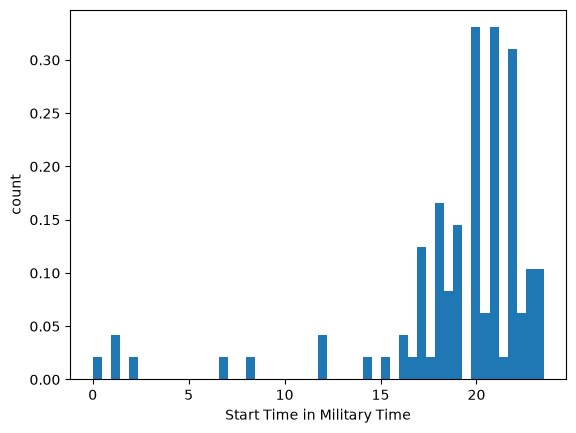

In [743]:
plt.hist(df['start_hour'], bins = 50, density= True, )
plt.xlabel("Start Time in Military Time")
plt.ylabel("count")

In [744]:
df["start_hour_model"] = df["start_hour"].where(
    df["start_hour"] >= 12,
    df["start_hour"] + 24
)# for model interpretability. 

<Axes: >

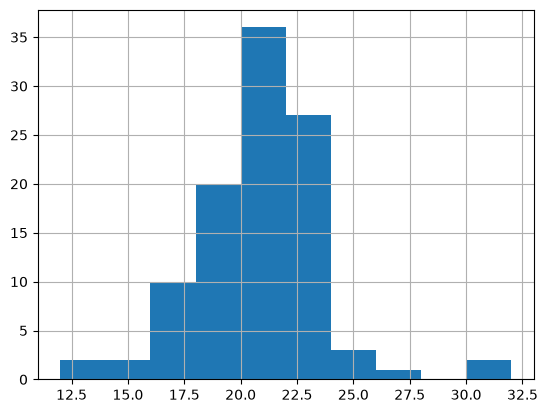

In [745]:
df['start_hour_model'].hist()

# 1 am is 3 hours away from 11 pm. but linear regression might treat the 1's (the AM's) as less than something like 11 pm or 23 in military time.

In [746]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
Where did you spend most of the night?                                         29
Did you pregame?                                                                2
How many people were in your group, including yourself?                         8
Who did you primarily spend the night with?                                    15
What was your pr

In [747]:
df['Where did you spend most of the night?'].unique()

array(['Bar or pub', 'Restaurant', 'Cafe', 'Nightclub',
       'Someone else’s home', 'Halfmoon bay', 'My home',
       'Outside in general', 'Party Bus', 'Dance ballroom', 'Mall',
       'Dowtown SF', 'University', 'Museum',
       'Its like a shopping commerce area so thered like bars and restaurants and places and things',
       'Movies and restaurant ', 'hotel', 'Table Tennis club',
       'Castro St. Block Party', 'Concert', 'gym/restaurant', 'Frats',
       'beach/ cave near the beach', 'Driving', 'Concert Venue',
       'USF campus', 'Castro Block Party',
       'Theater - we went to a concert', 'Outside'], dtype=object)

In [748]:
df['Where did you spend most of the night?'].nunique()

29

In [749]:
import pandas as pd
# mapping 
col = "Where did you spend most of the night?"

def clean_venue(value):
    if pd.isna(value):
        return "Unknown"

    s = str(value).strip().lower()

    # Bars and nightlife
    if s in ["bar or pub", "nightclub", "blue lagoon"]:
        return "Bar / Nightclub"

    # Restaurants and cafes
    if s in ["restaurant", "cafe"]:
        return "Restaurant / Cafe"

    # Private homes
    if s in ["my home", "someone else's home"]:
        return "Home"

    # Parties and organized events
    if s in [
        "party bus", "dance ballroom", "frats",
        "castro st. block party", "castro block party",
        "concert", "concert venue",
        "theater - we went to a concert"
    ]:
        return "Party / Event"

    # Outdoor/public spaces
    if s in [
        "outside", "outside in general",
        "beach/ cave near the beach", "driving"
    ]:
        return "Outdoors / Public"

    # Entertainment and public venues
    if s in [
        "mall", "museum", "table tennis club.",
        "university", "usf campus", "gym/restaurant"
    ]:
        return "Other Venue"

    # Specific area
    if s == "downtown sf":
        return "Downtown"

    # Anything not confidently classified
    return "Other / Unknown"


df["venue_clean"] = df[col].apply(clean_venue)

# Check the mapping
print(df["venue_clean"].value_counts())

# Identify responses that ended up in Other / Unknown
print(df.loc[df["venue_clean"] == "Other / Unknown", col].value_counts())

venue_clean
Bar / Nightclub      43
Other / Unknown      23
Restaurant / Cafe    15
Party / Event         8
Other Venue           6
Home                  4
Outdoors / Public     4
Name: count, dtype: int64
Where did you spend most of the night?
Someone else’s home                                                                            17
Halfmoon bay                                                                                    1
Dowtown SF                                                                                      1
Its like a shopping commerce area so thered like bars and restaurants and places and things     1
Movies and restaurant                                                                           1
hotel                                                                                           1
Table Tennis club                                                                               1
Name: count, dtype: int64


In [750]:
# Correct the remaining unmatched responses
fix_venues = {
    "Someone else’s home": "Home",
    "Halfmoon bay": "Outdoors / Public",
    "Dowtown SF": "Other / Unknown",
    "Its like a shopping commerce area so thered like bars and restaurants and places and things": "Bar / Nightclub",
    "Movies and restaurant": "Other Venue",
    "hotel": "Other Venue",
    "Table Tennis club": "Other Venue"
}

# Update the cleaned column using original responses
df["venue_clean"] = df["Where did you spend most of the night?"].map(
    fix_venues
).fillna(df["venue_clean"])

print(df["venue_clean"].value_counts())

venue_clean
Bar / Nightclub      44
Home                 21
Restaurant / Cafe    15
Party / Event         8
Other Venue           8
Outdoors / Public     5
Other / Unknown       2
Name: count, dtype: int64


In [751]:
df.loc[
    df["venue_clean"] == "Other / Unknown",
    "Where did you spend most of the night?"
].value_counts()

Where did you spend most of the night?
Dowtown SF                1
Movies and restaurant     1
Name: count, dtype: int64

In [752]:
col = "Where did you spend most of the night?"

df.loc[
    df[col].str.strip().str.lower() == "movies and restaurant",
    "venue_clean"
] = "Other Venue"

print(df["venue_clean"].value_counts())

venue_clean
Bar / Nightclub      44
Home                 21
Restaurant / Cafe    15
Other Venue           9
Party / Event         8
Outdoors / Public     5
Other / Unknown       1
Name: count, dtype: int64


In [753]:
col = "Where did you spend most of the night?"

# Convert responses to lowercase
venues = df[col].fillna("").str.lower()

# Create binary columns
df["visited_restaurant"] = venues.str.contains(
    "restaurant|cafe", regex=True
).astype(int)

df["visited_movies"] = venues.str.contains(
    "movie|theater", regex=True
).astype(int)

df["visited_bar"] = venues.str.contains(
    "bar|pub|nightclub", regex=True
).astype(int)

In [754]:
df.to_csv("survey_cleaned_backup.csv", index=False)

In [755]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
Where did you spend most of the night?                                         29
Did you pregame?                                                                2
How many people were in your group, including yourself?                         8
Who did you primarily spend the night with?                                    15
What was your pr

In [756]:
df[['venue_clean', 'Where did you spend most of the night?']]

,venue_clean,Where did you spend most of the night?
2,Bar / Nightclub,Bar or pub
3,Bar / Nightclub,Bar or pub
4,Restaurant / Cafe,Restaurant
5,Restaurant / Cafe,Cafe
6,Bar / Nightclub,Nightclub
...,...,...
102,Bar / Nightclub,Nightclub
103,Party / Event,Castro Block Party
104,Party / Event,Theater - we went to a concert
105,Outdoors / Public,Outside


In [757]:
df.drop(columns=['Where did you spend most of the night?', 'visited_restaurant', 'visited_movies', 'visited_bar'], inplace=True)

In [758]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
Did you pregame?                                                                2
How many people were in your group, including yourself?                         8
Who did you primarily spend the night with?                                    15
What was your primary mode of transportation?                                   5
Approximately ho

In [759]:
df.rename(columns = {"Did you pregame?" : "pregame"}, inplace=True)

In [760]:
df['pregame'].value_counts()

pregame
No     53
Yes    50
Name: count, dtype: int64

<Axes: xlabel='pregame', ylabel='count'>

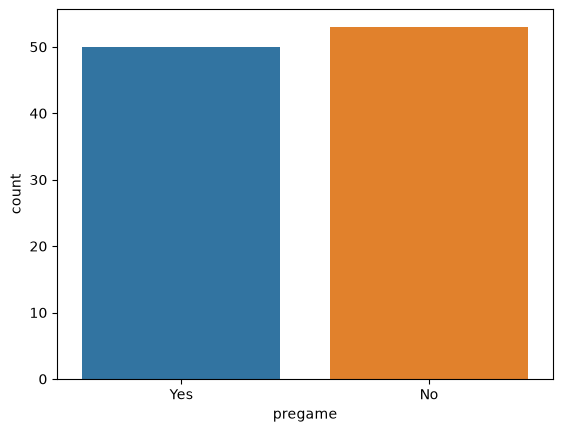

In [761]:
sns.countplot(data=df, x='pregame', hue='pregame') # nothing interesting going on here

In [762]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
How many people were in your group, including yourself?                         8
Who did you primarily spend the night with?                                    15
What was your primary mode of transportation?                                   5
Approximately ho

In [763]:
df['How many people were in your group, including yourself?'].unique()

array(['8+', '5', '1', '3', '4', '7', '2', '6'], dtype=object)

In [764]:
df['group_size'] = df['How many people were in your group, including yourself?'].replace({"8+":"8"}).astype(int)

In [765]:
df['group_size'].unique()

array([8, 5, 1, 3, 4, 7, 2, 6])

limitation, 8+ is labeled as 8 for ease of cleaning


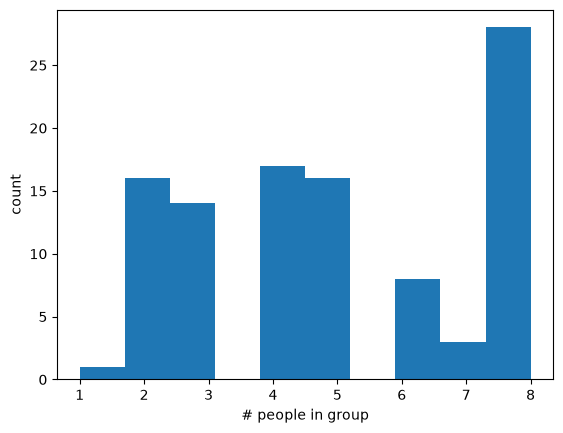

In [766]:
plt.hist(df['group_size'], bins = 10)
plt.ylabel('count')
plt.xlabel('# people in group')
print("limitation, 8+ is labeled as 8 for ease of cleaning")

In [767]:
df.corr(numeric_only=True)

,age,finance,plan_rating,Approximately how many hours did your night out last?,Approximately how much money did you personally spend (USD)?,"Overall, how enjoyable was this night out?",How long would your night out to be (in hours)?,Approximately how much money do you feel is needed for the night out (USD)?,height_cm,education_ranking,start_hour,start_hour_model,group_size
age,1.000000,-0.020291,0.067683,0.003208,0.168770,0.117793,-0.019466,0.172785,0.015287,0.492886,-0.064169,0.003060,0.016378
finance,-0.020291,1.000000,-0.075889,0.039154,0.121958,0.266882,-0.058546,0.168641,-0.093196,0.173840,0.104522,-0.169941,0.012159
plan_rating,0.067683,-0.075889,1.000000,0.058451,0.004258,-0.032784,-0.075784,-0.099256,-0.086931,0.080670,0.033659,-0.138959,0.233867
Approximately how many hours did your night out last?,0.003208,0.039154,0.058451,1.000000,0.255666,0.246433,0.488681,0.064307,-0.001115,0.124080,-0.208177,-0.004985,0.040139
Approximately how much money did you personally spend (USD)?,0.168770,0.121958,0.004258,0.255666,1.000000,0.063406,0.182855,0.529715,0.183066,0.301287,-0.195983,-0.080401,-0.076931
"Overall, how enjoyable was this night out?",0.117793,0.266882,-0.032784,0.246433,0.063406,1.000000,0.283534,0.099765,-0.055325,0.240333,0.018937,-0.101190,-0.168637
How long would your night out to be (in hours)?,-0.019466,-0.058546,-0.075784,0.488681,0.182855,0.283534,1.000000,0.188974,0.001470,0.201117,-0.183884,-0.095933,-0.128984
Approximately how much money do you feel is needed for the night out (USD)?,0.172785,0.168641,-0.099256,0.064307,0.529715,0.099765,0.188974,1.000000,0.006349,0.204084,-0.088108,-0.073074,-0.077409
height_cm,0.015287,-0.093196,-0.086931,-0.001115,0.183066,-0.055325,0.001470,0.006349,1.000000,-0.143402,-0.090537,-0.081267,0.003332
education_ranking,0.492886,0.173840,0.080670,0.124080,0.301287,0.240333,0.201117,0.204084,-0.143402,1.000000,-0.205645,0.111563,-0.038934


In [768]:
df.shape
df.drop(columns="How many people were in your group, including yourself?", inplace = True)

In [769]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
Who did you primarily spend the night with?                                    15
What was your primary mode of transportation?                                   5
Approximately how many hours did your night out last?                          10
At approximately

In [770]:
df['Who did you primarily spend the night with?'].unique()

array(['Friends, Romantic partner or date, Mixed group / Other',
       'Friends, Family', 'Friends', 'Alone',
       'Friends, Mixed group / Other',
       'Friends, Romantic partner or date',
       'Romantic partner or date, Family', 'Romantic partner or date',
       'Friends, Coworkers or acquaintances', 'Alone, Friends', 'Family',
       'Friends, Romantic partner or date, Coworkers or acquaintances',
       'Coworkers or acquaintances',
       'Friends, Romantic partner or date, Family',
       'Coworkers or acquaintances, Mixed group / Other'], dtype=object)

In [771]:
df['Who did you primarily spend the night with?'].value_counts()

Who did you primarily spend the night with?
Friends                                                          57
Friends, Romantic partner or date                                12
Romantic partner or date                                          7
Friends, Coworkers or acquaintances                               7
Friends, Mixed group / Other                                      5
Family                                                            3
Friends, Romantic partner or date, Mixed group / Other            2
Alone                                                             2
Alone, Friends                                                    2
Friends, Family                                                   1
Romantic partner or date, Family                                  1
Friends, Romantic partner or date, Coworkers or acquaintances     1
Coworkers or acquaintances                                        1
Friends, Romantic partner or date, Family                         1
Cowo

In [772]:
col = "Who did you primarily spend the night with?"

categories = {
    "with_friends": "Friends",
    "with_partner": "Romantic partner or date",
    "with_family": "Family",
    "with_coworkers": "Coworkers or acquaintances",
    "with_mixed_other": "Mixed group / Other",
    "with_alone": "Alone"
}

# Create binary columns
for new_col, category in categories.items():
    df[new_col] = df[col].fillna("").str.split(", ").apply(
        lambda x: int(category in x)
    )

# Verify the results
print(df[list(categories)].sum())

with_friends        88
with_partner        24
with_family          6
with_coworkers      10
with_mixed_other     8
with_alone           4
dtype: int64


In [773]:
88+24

112

In [774]:
df.drop(columns="Who did you primarily spend the night with?", inplace = True)

In [775]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
What was your primary mode of transportation?                                   5
Approximately how many hours did your night out last?                          10
At approximately what time did your night end?                                 30
Approximately ho

In [776]:
df['What was your primary mode of transportation?'].unique() #nominal data, has no inherent order

array(['Ride-share / Taxi', 'Riding with someone else', 'Driving myself',
       'Public transportation', 'Walking'], dtype=object)

In [777]:
df.rename(columns = {"What was your primary mode of transportation?" : "transportation"}, inplace=True)

transportation
Ride-share / Taxi           33
Public transportation       27
Walking                     19
Riding with someone else    13
Driving myself              11
Name: count, dtype: int64


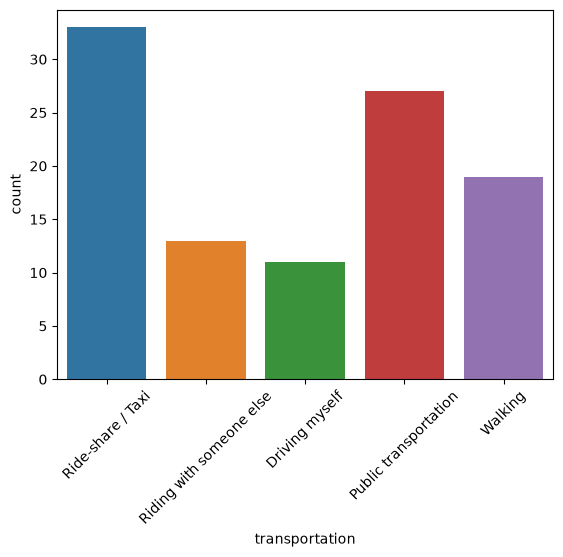

In [778]:
sns.countplot(data = df, x= 'transportation', hue='transportation')
plt.xticks(rotation = 45)
print(df.transportation.value_counts().sort_values(ascending=False))

In [779]:
df['Approximately how many hours did your night out last?'].unique()

array([ 5. ,  6. ,  3. ,  4. ,  8. ,  7. ,  2. , 10. ,  4.5,  1. ])

<Axes: >

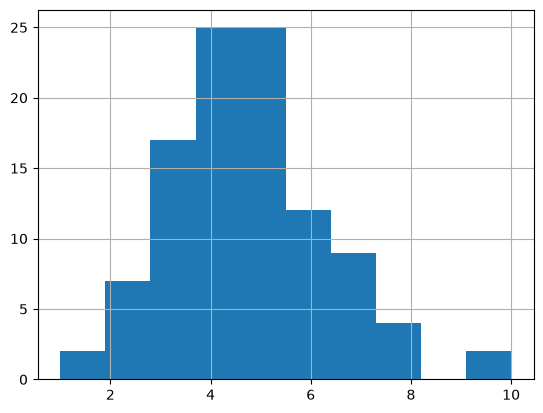

In [780]:
df['Approximately how many hours did your night out last?'].hist()

In [781]:
df.rename(columns={"Approximately how many hours did your night out last?" : "hours_out"}, inplace = True)

In [782]:
df.hours_out.nunique()

10

In [783]:
df.hours_out.isna().sum()

np.int64(0)

In [784]:
df.hours_out.value_counts().sum() # checks out: hours out follows a roughly normal distribution

np.int64(103)

In [785]:
df.hours_out.describe()

count    103.000000
mean       4.665049
std        1.738250
min        1.000000
25%        3.500000
50%        5.000000
75%        6.000000
max       10.000000
Name: hours_out, dtype: float64

In [786]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
At approximately what time did your night end?                                 30
Approximately ho

In [787]:
df['At approximately what time did your night end?'].unique()  

array(['3:00:00 AM', '1:00:00 AM', '10:20:00 PM', '5:00:00 PM',
       '1:50:00 AM', '2:00:00 AM', '1:30:00 PM', '4:00:00 AM',
       '1:40:00 AM', '10:00:00 AM', '11:00:00 PM', '12:30:00 AM',
       '12:00:00 AM', '12:30:00 PM', '1:30:00 AM', '9:00:00 PM',
       '7:00:00 PM', '10:00:00 PM', '8:30:00 PM', '9:30:00 PM',
       '8:40:00 AM', '11:30:00 PM', '7:30:00 PM', '5:00:00 AM',
       '2:30:00 AM', '5:30:00 PM', '4:09:00 AM', '2:00:00 PM',
       '8:00:00 PM', '3:30:00 AM'], dtype=object)

In [788]:
df.rename(columns = {'At approximately what time did your night end?': "night_end_hour"}, inplace = True)

In [789]:
df.night_end_hour

2       3:00:00 AM
3       1:00:00 AM
4      10:20:00 PM
5       5:00:00 PM
6       1:50:00 AM
          ...     
102     3:30:00 AM
103    11:00:00 PM
104     1:00:00 AM
105     2:00:00 AM
106     2:30:00 AM
Name: night_end_hour, Length: 103, dtype: object

In [790]:
# Step 1: Convert text into datetime objects
times = pd.to_datetime(
    df["night_end_hour"],
    format="%I:%M:%S %p",
    errors="coerce"
)

# Step 2: Convert to decimal hours
# Example: 9:30 PM → 21 + 30/60 = 21.5
df["nightend"] = times.dt.hour + times.dt.minute / 60

# Step 3: Adjust times after midnight
# Example: 1 AM → 1 + 24 = 25
df["nightend"] = df["nightend"].where(
    df["nightend"] >= 12,
    df["nightend"] + 24
)

#script

# Inspect results
print(df[["night_end_hour", "nightend"]].head(10))

   night_end_hour   nightend
2      3:00:00 AM  27.000000
3      1:00:00 AM  25.000000
4     10:20:00 PM  22.333333
5      5:00:00 PM  17.000000
6      1:50:00 AM  25.833333
7      2:00:00 AM  26.000000
8      2:00:00 AM  26.000000
9      3:00:00 AM  27.000000
10     3:00:00 AM  27.000000
11     2:00:00 AM  26.000000


<Axes: >

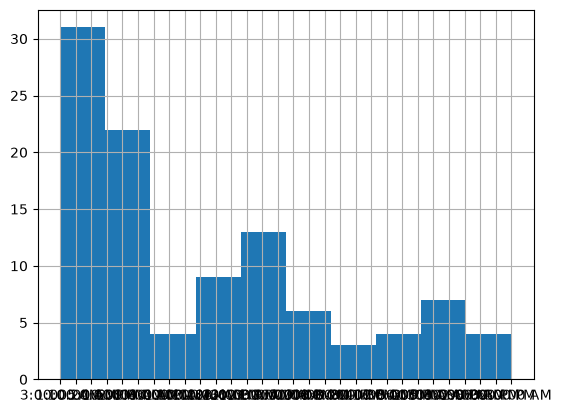

In [791]:
df['night_end_hour'].hist()

<Axes: >

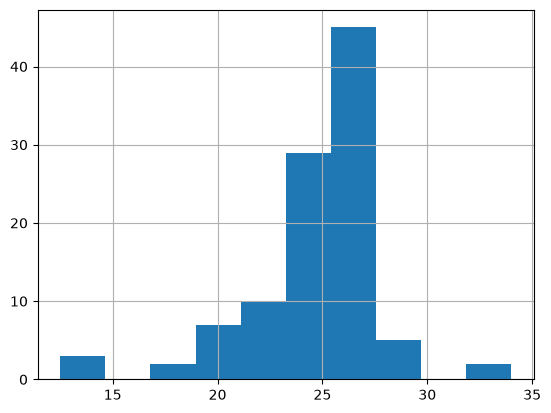

In [792]:
df['nightend'].hist()

In [793]:
#makes sense, they're inverted 

df.drop(columns="night_end_hour", inplace=True)

In [794]:
df.nightend

2      27.000000
3      25.000000
4      22.333333
5      17.000000
6      25.833333
         ...    
102    27.500000
103    23.000000
104    25.000000
105    26.000000
106    26.500000
Name: nightend, Length: 103, dtype: float64

In [795]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
Approximately how much money did you personally spend (USD)?                   32
Did you consume 

In [796]:
df.rename(columns={'Approximately how much money did you personally spend (USD)?': 'money_spent_usd'}, inplace=True)

<Axes: >

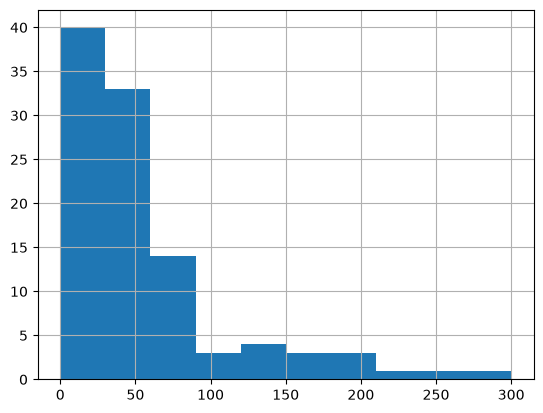

In [797]:
df.money_spent_usd.hist()

In [798]:
df.money_spent_usd.describe() # nothing interesting here as far as data cleaning goes. EDA later

count    103.000000
mean      51.912621
std       57.268735
min        0.000000
25%       15.000000
50%       35.000000
75%       70.000000
max      300.000000
Name: money_spent_usd, dtype: float64

In [799]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
Did you consume 

In [800]:
df.rename(columns = {'Did you consume any alcohol during this night out?': "alcohol_consumed"}, inplace=True)

alcohol_consumed
Yes    72
No     31
Name: count, dtype: int64

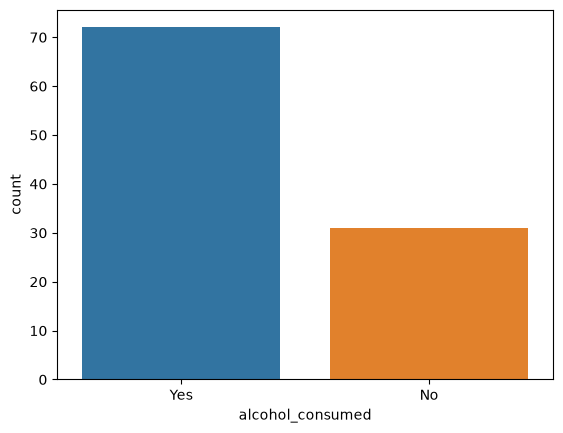

In [801]:
sns.countplot(data= df, x = 'alcohol_consumed', hue = 'alcohol_consumed')
df.alcohol_consumed.value_counts()

Did you consume substances other than alcohol?
No     78
Yes    25
Name: count, dtype: int64

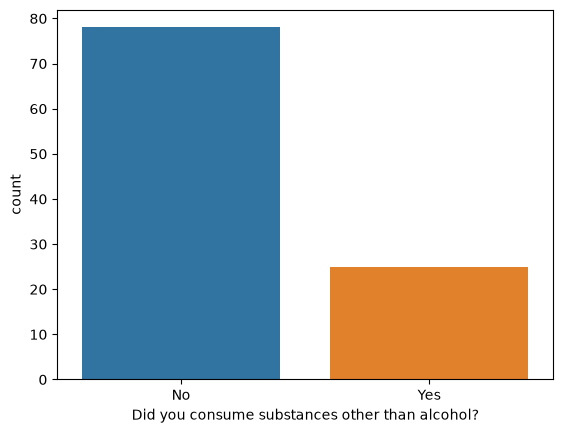

In [802]:
sns.countplot(data = df, x= 'Did you consume substances other than alcohol?', hue = 'Did you consume substances other than alcohol?')
df['Did you consume substances other than alcohol?'].value_counts()

In [803]:
df.rename(columns={"Did you consume substances other than alcohol?": "nonAlcoholic_substance"}, inplace = True)

In [804]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
alcohol_consumed

In [805]:
df['Did you end the night...'].unique()

array(['Tipsy', 'Drunk', 'Sober', 'Tispy and Non-Sober',
       'Drunk and Non-Sober', 'Non-Sober'], dtype=object)

In [806]:
df.rename(columns = {"Did you end the night..." : "sobriety_level_night"}, inplace = True)

In [807]:
sobriety_map = {
    "Sober": "Sober",
    "Non-Sober": "Unspecified intoxication",
    "Tipsy": "Tipsy",
    "Tipsy and Non-Sober": "Tipsy",
    "Drunk": "Drunk",
    "Drunk and Non-Sober": "Drunk"
}

df["sobriety_clean"] = df["sobriety_level_night"].map(sobriety_map)

print(df["sobriety_clean"].value_counts(dropna=False))

sobriety_clean
Sober                       40
Drunk                       30
Tipsy                       20
NaN                          9
Unspecified intoxication     4
Name: count, dtype: int64


sobriety_level_night
Sober                  40
Tipsy                  20
Drunk                  19
Drunk and Non-Sober    11
Tispy and Non-Sober     9
Non-Sober               4
Name: count, dtype: int64

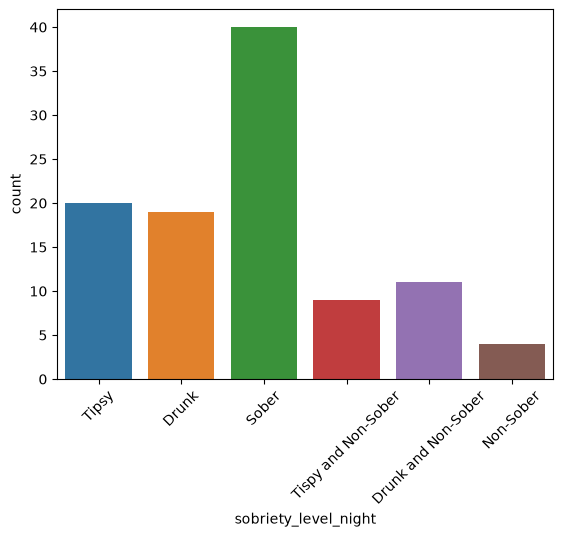

In [808]:
sns.countplot(data=df, x = "sobriety_level_night", hue = 'sobriety_level_night')
plt.xticks(rotation = 45)
df.sobriety_level_night.value_counts()

In [809]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
alcohol_consumed

In [810]:
df.rename(columns = {"How many different venues or locations did you visit?": "locations_or_venues_visited"}, inplace = True)

(array([33.,  0.,  0., 33.,  0.,  0., 29.,  0.,  0.,  6.,  0.,  0.,  1.,
         0.,  1.]),
 array([0.        , 0.33333333, 0.66666667, 1.        , 1.33333333,
        1.66666667, 2.        , 2.33333333, 2.66666667, 3.        ,
        3.33333333, 3.66666667, 4.        , 4.33333333, 4.66666667,
        5.        ]),
 <BarContainer object of 15 artists>)

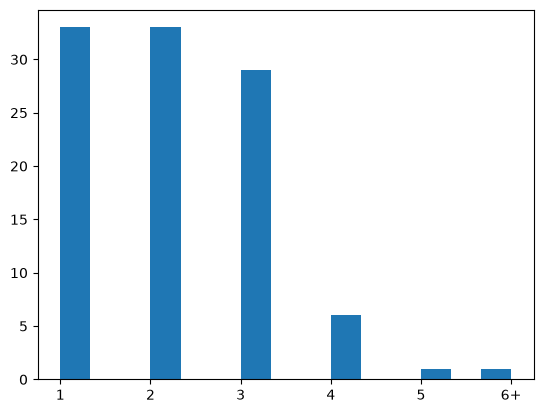

In [811]:

plt.hist(df['locations_or_venues_visited'].sort_values(), bins = 15)

In [812]:
df['locations_or_venues_visited'].value_counts()

locations_or_venues_visited
2     33
1     33
3     29
4      6
6+     1
5      1
Name: count, dtype: int64

In [813]:
df['locations_or_venues_visited'] = df['locations_or_venues_visited'].replace({'6+': '6'}).astype(int)

In [814]:
df['locations_or_venues_visited'].value_counts()

locations_or_venues_visited
2    33
1    33
3    29
4     6
6     1
5     1
Name: count, dtype: int64

In [815]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
alcohol_consumed

In [816]:
df['At the end of the night, did you have something to eat?'].unique()

array(['Yes, Something at home (you made something)', 'No',
       'Yes, Food delivery (e.g. Doordash)', 'Yes, Late night restaurant'],
      dtype=object)

In [817]:
df.rename(columns={'At the end of the night, did you have something to eat?': 'eat_end_of_night'}, inplace = True)

In [818]:
df.eat_end_of_night.value_counts()

eat_end_of_night
No                                             29
Yes, Late night restaurant                     29
Yes, Something at home (you made something)    26
Yes, Food delivery (e.g. Doordash)             19
Name: count, dtype: int64

In [819]:
# Map each response to a new binary column
eat_map = {
    "ate_nothing": "No",
    "ate_at_home": "Yes, Something at home (you made something)",
    "ate_delivery": "Yes, Food delivery (e.g. Doordash)",
    "ate_restaurant": "Yes, Late night restaurant"
}

# Create the columns
for new_col, category in eat_map.items():
    df[new_col] = (df["eat_end_of_night"] == category).astype(int)

# Verify
print(df[list(eat_map)].sum())

ate_nothing       29
ate_at_home       26
ate_delivery      19
ate_restaurant    29
dtype: int64


In [820]:
df.drop(columns='eat_end_of_night', inplace=True)

In [821]:
df.rename(columns={"Overall, how enjoyable was this night out?": 'y'}, inplace = True)

<Axes: >

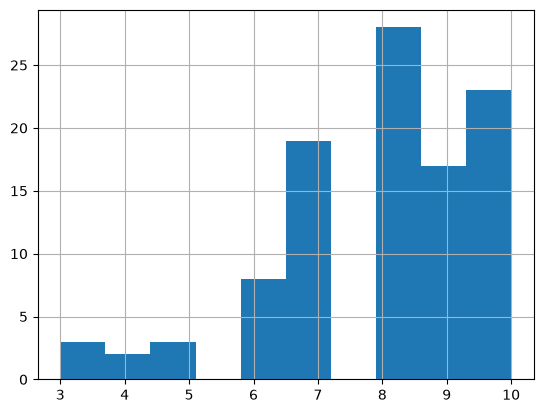

In [822]:
df.y.hist()

In [823]:
df.drop(columns="What day of the week would this night out take place?", inplace=True)

In [824]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
alcohol_consumed

In [825]:
df['How planned would this night out be?'].unique() # redudant, drop

array(['Partially planned (there was an idea that would be executed)',
       'Planned well in advanced (you would know with at least a couple days notice)',
       'Not planned at all (spontaneous)'], dtype=object)

In [826]:
df.drop(columns='How planned would this night out be?', inplace=True)

In [827]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
alcohol_consumed

In [828]:
df['What time would you want your night out to begin?'].unique()

array(['10:00:00 PM', '7:00:00 PM', '6:00:00 PM', '8:00:00 PM',
       '11:00:00 PM', '9:00:00 PM', '10:00:00 AM', '5:00:00 PM',
       '10:30:00 PM', '7:00:00 AM', '8:30:00 AM', '2:00:00 PM',
       '9:30:00 PM', '7:30:00 PM', '5:30:00 PM', '8:30:00 PM',
       '11:00:00 AM'], dtype=object)

<Axes: >

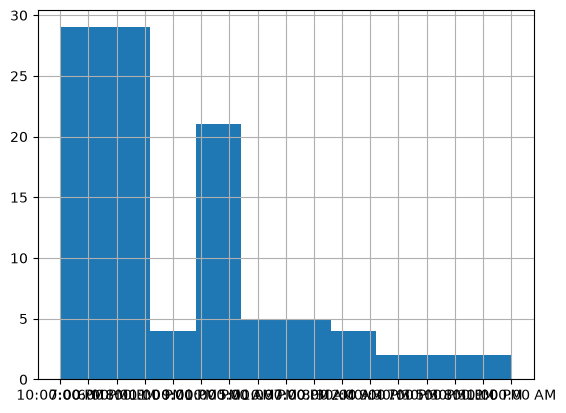

In [829]:
df['What time would you want your night out to begin?'].hist()

<Axes: >

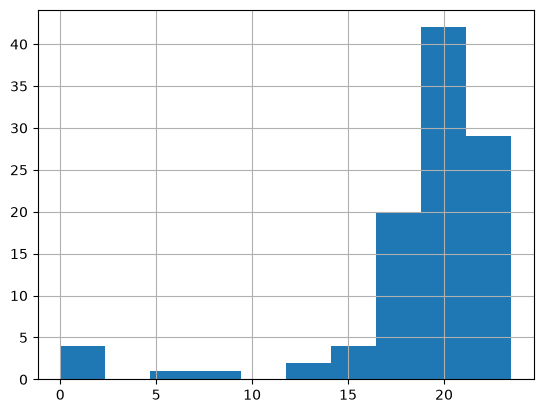

In [830]:
df.start_hour.hist() # conclusion: redundant, as they are close to each other

In [831]:
df.drop(columns={'What time would you want your night out to begin?'}, inplace=True)

In [832]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
alcohol_consumed

count    103.000000
mean       4.888350
std        1.926253
min        1.000000
25%        4.000000
50%        5.000000
75%        6.000000
max       12.000000
Name: How long would your night out to be (in hours)?, dtype: float64

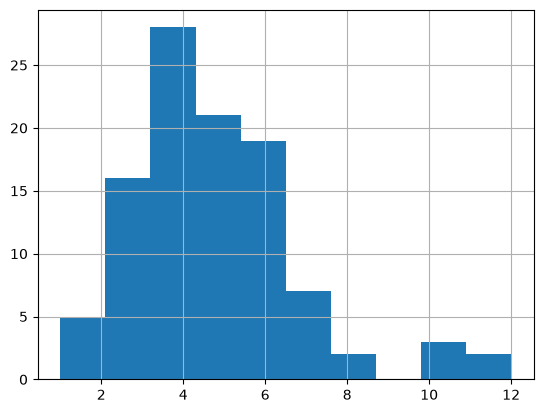

In [833]:
df['How long would your night out to be (in hours)?'].hist()
df['How long would your night out to be (in hours)?'].describe()

count    103.000000
mean       4.665049
std        1.738250
min        1.000000
25%        3.500000
50%        5.000000
75%        6.000000
max       10.000000
Name: hours_out, dtype: float64

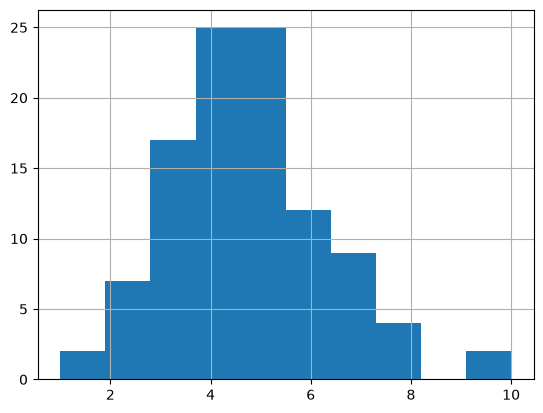

In [834]:
df.hours_out.hist()
df.hours_out.describe()

In [835]:
# again, redundant, carries roughly same info
df.drop(columns='How long would your night out to be (in hours)?', inplace=True)

In [836]:
df.drop(columns='At the end of the night, would you want to have something to eat?', inplace=True)

In [837]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
alcohol_consumed

<Axes: >

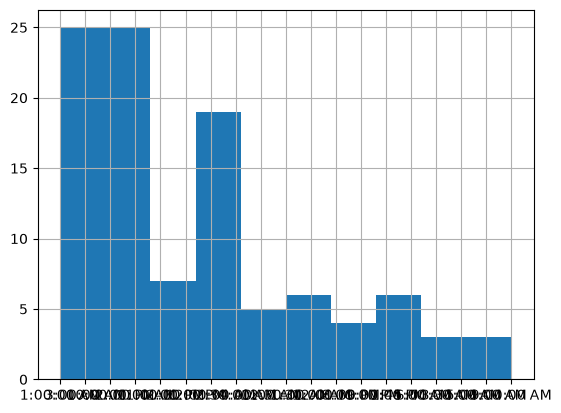

In [838]:
df['What time would your night end?'].hist()

In [839]:
df.rename(columns={'What time would your night end?': "night_end_time"}, inplace = True)

In [840]:
df.night_end_time.unique()

array(['1:00:00 AM', '3:00:00 AM', '10:00:00 PM', '2:00:00 AM',
       '11:00:00 PM', '2:00:00 PM', '12:00:00 AM', '2:30:00 AM',
       '4:00:00 AM', '12:30:00 AM', '1:30:00 AM', '12:00:00 PM',
       '8:00:00 PM', '9:00:00 PM', '1:45:00 AM', '6:00:00 AM',
       '3:30:00 AM', '5:00:00 AM', '9:00:00 AM'], dtype=object)

In [841]:
import pandas as pd

# Step 1: Convert text into datetime objects
times = pd.to_datetime(
    df["night_end_time"],
    format="%I:%M:%S %p",
    errors="coerce"
)

# Step 2: Convert into decimal hours
df["night_end_hour"] = (
    times.dt.hour + times.dt.minute / 60
)

# Step 3: Adjust times after midnight
df["night_end_hour_model"] = df["night_end_hour"].where(
    df["night_end_hour"] >= 12,
    df["night_end_hour"] + 24
)

# Step 4: Verify
print(df[["night_end_time", "night_end_hour", "night_end_hour_model"]].head(10))

   night_end_time  night_end_hour  night_end_hour_model
2      1:00:00 AM             1.0                  25.0
3      3:00:00 AM             3.0                  27.0
4     10:00:00 PM            22.0                  22.0
5      2:00:00 AM             2.0                  26.0
6     11:00:00 PM            23.0                  23.0
7      1:00:00 AM             1.0                  25.0
8      2:00:00 AM             2.0                  26.0
9      2:00:00 AM             2.0                  26.0
10     3:00:00 AM             3.0                  27.0
11     2:00:00 AM             2.0                  26.0


In [842]:
df.drop(columns={"night_end_time", 'night_end_hour',}, inplace = True)

In [843]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
alcohol_consumed

In [844]:
df.rename(columns = {'under influence': "under_influence"}, inplace = True)

In [845]:
df['Where would you like to spend most of the night?'].unique()

array(['Restaurant', 'Nightclub', 'My home or someone else’s home',
       'Bar or pub', 'Other', 'Cafe'], dtype=object)

In [846]:
mapper = {
    "Restaurant": "Restaurant",
    "Nightclub": "Nightclub",
    "My home or someone else’s home": "Home",
    "Bar or pub": "Bar",
    "Other": "Other",
    "Cafe": "Cafe"
}

col = "Where would you like to spend most of the night?"

df["preferred_venue"] = df[col].map(mapper)

# Verify mapping
print(df["preferred_venue"].value_counts(dropna=False))

preferred_venue
Home          40
Bar           25
Restaurant    15
Nightclub     15
Other          7
Cafe           1
Name: count, dtype: int64


In [847]:
df["preferred_venue"].value_counts().sum()

np.int64(103)

In [848]:
df.drop(columns={'Where would you like to spend most of the night?'}, inplace=True)

In [849]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under_influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
alcohol_consumed

In [850]:
df['Would a pregame be a necessity for your night out?'].value_counts()

Would a pregame be a necessity for your night out?
No     61
Yes    42
Name: count, dtype: int64

In [851]:
df['pregame'].value_counts()

pregame
No     53
Yes    50
Name: count, dtype: int64

In [852]:
df.rename(columns={'Would a pregame be a necessity for your night out?':'pregame_needed_?'}, inplace=True)

In [853]:
df.rename(columns={'pregame_needed_?':'pregame_needed_q'}, inplace=True)

In [854]:
df.pregame_needed_q

2       No
3      Yes
4       No
5       No
6       No
      ... 
102     No
103     No
104     No
105     No
106    Yes
Name: pregame_needed_q, Length: 103, dtype: object

In [855]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under_influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
alcohol_consumed

In [856]:
df['How many people is ideal for the perfect night out?'].str.replace('8+','8').astype(int).unique()

array([0, 6, 4, 2, 3, 5, 8, 7])

In [857]:
df["ideal_group_size"] = df["How many people is ideal for the perfect night out?"].str.replace("8+", "8", regex=False).astype(int)

count    103.000000
mean       4.660194
std        1.695168
min        0.000000
25%        4.000000
50%        4.000000
75%        6.000000
max        8.000000
Name: ideal_group_size, dtype: float64

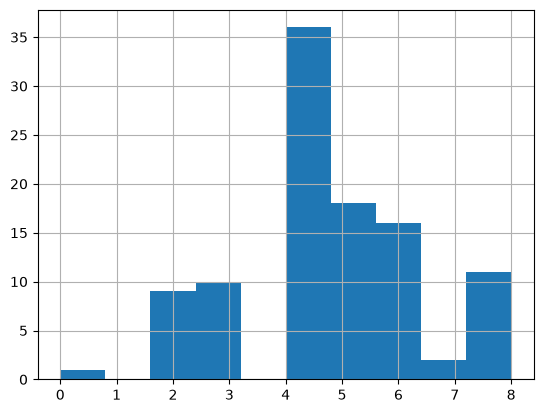

In [858]:
df["ideal_group_size"].hist()
df["ideal_group_size"].describe()

count    103.000000
mean       5.009709
std        2.225058
min        1.000000
25%        3.000000
50%        5.000000
75%        8.000000
max        8.000000
Name: group_size, dtype: float64

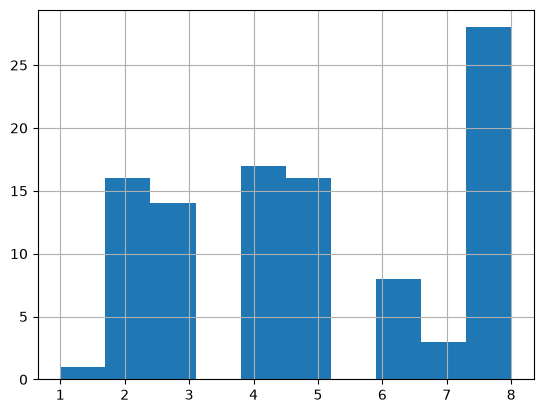

In [859]:
df.group_size.hist()
df.group_size.describe()

In [860]:
df.drop(columns={'How many people is ideal for the perfect night out?'}, inplace=True)

In [861]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under_influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
alcohol_consumed

In [862]:
df.head()

,21?,night_out_last30,under_influence,age,gender,finance,day_of_week,plan_rating,pregame,transportation,...,with_alone,nightend,sobriety_clean,ate_nothing,ate_at_home,ate_delivery,ate_restaurant,night_end_hour_model,preferred_venue,ideal_group_size
2,Yes,Yes,No,21.0,Male,4.0,Friday,3,Yes,Ride-share / Taxi,...,0,27.000000,Tipsy,0,1,0,0,25.0,Restaurant,0
3,Yes,Yes,No,21.0,Male,3.0,Saturday,4,Yes,Ride-share / Taxi,...,0,25.000000,Drunk,0,1,0,0,27.0,Nightclub,6
4,Yes,Yes,No,22.0,Female,2.0,Wednesday,4,No,Riding with someone else,...,0,22.333333,Sober,1,0,0,0,22.0,Home,4
5,Yes,Yes,No,21.0,Male,5.0,Saturday,2,No,Ride-share / Taxi,...,1,17.000000,Sober,0,0,1,0,26.0,Restaurant,2
6,Yes,No,No,22.0,Female,4.0,Friday,1,No,Driving myself,...,0,25.833333,Tipsy,0,0,0,1,23.0,Restaurant,2


In [863]:
df.to_csv("clean2.csv", index = False)

In [864]:
df['What type of people would be ideal?'].unique()

array(['Alone', 'Friends, Family', 'Friends',
       'Friends, Mixed group / Other',
       'Friends, Romantic partner or date, Family, Coworkers or acquaintances',
       'Friends, Romantic partner or date, Family',
       'Alone, Friends, Romantic partner or date, Family, Mixed group / Other',
       'Friends, Coworkers or acquaintances, Mixed group / Other',
       'Friends, Romantic partner or date',
       'Friends, Coworkers or acquaintances',
       'Friends, Romantic partner or date, Mixed group / Other',
       'Alone, Friends, Family, Coworkers or acquaintances',
       'Friends, Romantic partner or date, Family, Mixed group / Other',
       'Friends, Romantic partner or date, Family, Coworkers or acquaintances, Mixed group / Other',
       'Friends, Family, Coworkers or acquaintances',
       'Friends, Romantic partner or date, Coworkers or acquaintances',
       'Romantic partner or date',
       'Friends, Romantic partner or date, Coworkers or acquaintances, Mixed group / 

In [865]:
df.drop(columns = {"What type of people would be ideal?"}, inplace=True)

In [866]:
df.nunique()

21?                                                                             2
night_out_last30                                                                2
under_influence                                                                 2
age                                                                            16
gender                                                                          3
finance                                                                         5
day_of_week                                                                     7
plan_rating                                                                     4
pregame                                                                         2
transportation                                                                  5
hours_out                                                                      10
money_spent_usd                                                                32
alcohol_consumed

count    103.000000
mean      51.912621
std       57.268735
min        0.000000
25%       15.000000
50%       35.000000
75%       70.000000
max      300.000000
Name: money_spent_usd, dtype: float64

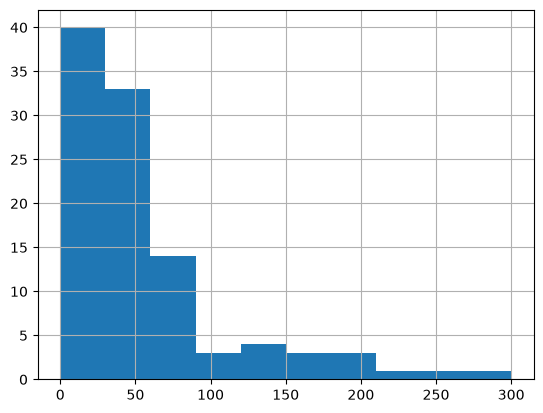

In [867]:
df.money_spent_usd.hist()
df.money_spent_usd.describe()

count    103.000000
mean      63.592233
std       64.808986
min        0.000000
25%       25.000000
50%       50.000000
75%       80.000000
max      500.000000
Name: Approximately how much money do you feel is needed for the night out (USD)?, dtype: float64

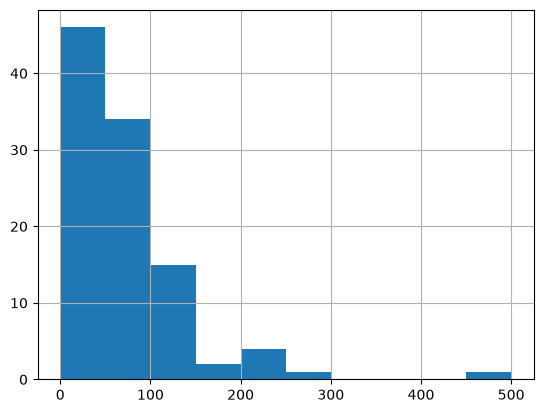

In [868]:
df['Approximately how much money do you feel is needed for the night out (USD)?'].hist()
df['Approximately how much money do you feel is needed for the night out (USD)?'].describe()

In [869]:
#keep this column because the difference from their actual money spent is significantly different
df.rename(columns={'Approximately how much money do you feel is needed for the night out (USD)?': 'money_needed_night_out'}, inplace=True)

In [870]:
df.nunique()

21?                                                                    2
night_out_last30                                                       2
under_influence                                                        2
age                                                                   16
gender                                                                 3
finance                                                                5
day_of_week                                                            7
plan_rating                                                            4
pregame                                                                2
transportation                                                         5
hours_out                                                             10
money_spent_usd                                                       32
alcohol_consumed                                                       2
nonAlcoholic_substance                             

In [871]:
df['What would be the best way to get around during your night out?'].unique()

array(['Ride-share / Taxi', 'Walking', 'Riding with someone else',
       'Driving myself', 'Public transportation', 'Bicycle / Other'],
      dtype=object)

In [872]:
df.rename(columns={'What would be the best way to get around during your night out?':'method_of_tranportation'}, inplace = True)

In [873]:
transport_map = {
    "Ride-share / Taxi": "Rideshare",
    "Walking": "Walking",
    "Riding with someone else": "Passenger",
    "Driving myself": "Driving",
    "Public transportation": "Public Transit",
    "Bicycle / Other": "Bicycle / Other"
}

# Create cleaned column
df["transport_clean"] = df["method_of_tranportation"].map(transport_map)

# Verify
print(df["transport_clean"].value_counts(dropna=False))

transport_clean
Public Transit     31
Rideshare          27
Walking            18
Passenger          16
Driving            10
Bicycle / Other     1
Name: count, dtype: int64


In [874]:
df.drop(columns={"method_of_tranportation"}, inplace = True)

In [875]:
df.nunique()

21?                                                                    2
night_out_last30                                                       2
under_influence                                                        2
age                                                                   16
gender                                                                 3
finance                                                                5
day_of_week                                                            7
plan_rating                                                            4
pregame                                                                2
transportation                                                         5
hours_out                                                             10
money_spent_usd                                                       32
alcohol_consumed                                                       2
nonAlcoholic_substance                             

Would you need to consume alcohol (in any capacity)?
No     52
Yes    51
Name: count, dtype: int64

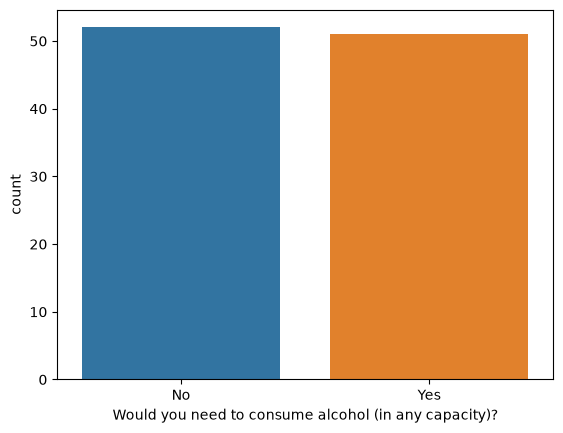

In [876]:
sns.countplot(data=df, x='Would you need to consume alcohol (in any capacity)?',hue='Would you need to consume alcohol (in any capacity)?')
df['Would you need to consume alcohol (in any capacity)?'].value_counts()

In [877]:
df.rename(columns={"Would you need to consume alcohol (in any capacity)?":"alcohol_needed_q"}, inplace = True)

In [878]:
df.nunique()

21?                                                                    2
night_out_last30                                                       2
under_influence                                                        2
age                                                                   16
gender                                                                 3
finance                                                                5
day_of_week                                                            7
plan_rating                                                            4
pregame                                                                2
transportation                                                         5
hours_out                                                             10
money_spent_usd                                                       32
alcohol_consumed                                                       2
nonAlcoholic_substance                             

In [879]:
df['Would you need to consume any other substances other than alcohol?'].unique()

array(['No', 'Yes', 'Maybe'], dtype=object)

Would you need to consume any other substances other than alcohol?
No       65
Maybe    25
Yes      13
Name: count, dtype: int64

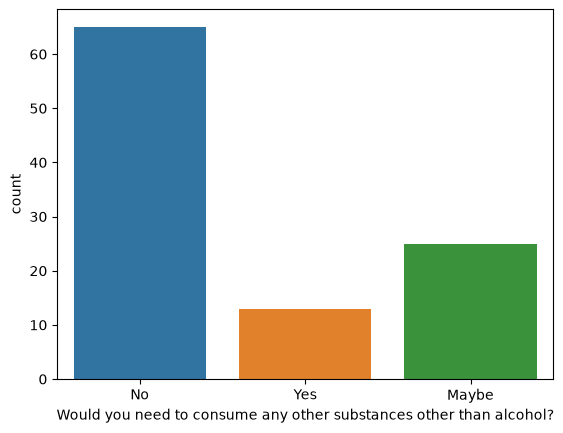

In [880]:
sns.countplot(data=df, x='Would you need to consume any other substances other than alcohol?', hue='Would you need to consume any other substances other than alcohol?')
df['Would you need to consume any other substances other than alcohol?'].value_counts()

In [881]:
df.groupby('y')['Would you need to consume any other substances other than alcohol?'].count()

y
3.0      3
4.0      2
5.0      3
6.0      8
7.0     19
8.0     28
9.0     17
10.0    23
Name: Would you need to consume any other substances other than alcohol?, dtype: int64

In [882]:
col = "Would you need to consume any other substances other than alcohol?"

df["substance_preference"] = pd.Categorical(
    df[col],
    categories=["No", "Maybe", "Yes"]
)

dummies = pd.get_dummies(
    df["substance_preference"],
    prefix="substance",
    drop_first=True,
    dtype=int
)

df = pd.concat([df, dummies], axis=1)

In [883]:
print(df[["substance_Maybe", "substance_Yes"]].sum())

substance_Maybe    25
substance_Yes      13
dtype: int64


In [884]:
25+13

38

In [885]:
103-38 # successful conversion

65

In [886]:
df.drop(columns={"Would you need to consume any other substances other than alcohol?"}, inplace=True)

In [887]:
df['Does your perfect night end with you being...'].unique()

array(['Tipsy', 'Sober', 'Tipsy and Non-sober', 'Drunk and Non-sober',
       'Drunk', 'Non-Sober'], dtype=object)

In [888]:
df.substance_preference.unique()

['No', 'Yes', 'Maybe']
Categories (3, object): ['No', 'Maybe', 'Yes']

In [889]:
df.drop(columns = {'substance_preference'}, inplace=True)

In [892]:
df.nunique()

21?                                               2
night_out_last30                                  2
under_influence                                   2
age                                              16
gender                                            3
finance                                           5
day_of_week                                       7
plan_rating                                       4
pregame                                           2
transportation                                    5
hours_out                                        10
money_spent_usd                                  32
alcohol_consumed                                  2
nonAlcoholic_substance                            2
sobriety_level_night                              6
locations_or_venues_visited                       6
y                                                 8
pregame_needed_q                                  2
money_needed_night_out                           22
alcohol_need

In [891]:
df.sobriety_clean.unique()
#df.drop(columns={'sobriety_clean'}, inplace = True)

array(['Tipsy', 'Drunk', 'Sober', nan, 'Unspecified intoxication'],
      dtype=object)

In [893]:
col = "Does your perfect night end with you being..."

sobriety_map = {
    "Sober": "Sober",
    "Tipsy": "Tipsy",
    "Tipsy and Non-Sober": "Tipsy",
    "Drunk": "Drunk",
    "Drunk and Non-Sober": "Drunk",
    "Non-Sober": "Unspecified Intoxication"
}

# Create the new column
df["sobriety_ideal"] = df[col].map(sobriety_map)

# Verify the mapping
print(df["sobriety_ideal"].value_counts(dropna=False))

sobriety_ideal
Sober                       37
Tipsy                       31
NaN                         21
Drunk                       12
Unspecified Intoxication     2
Name: count, dtype: int64


In [894]:
37+31+21+12+2

103

In [898]:
df.drop(columns={'Does your perfect night end with you being...'}, inplace=True)

In [899]:
df.nunique()

21?                                             2
night_out_last30                                2
under_influence                                 2
age                                            16
gender                                          3
finance                                         5
day_of_week                                     7
plan_rating                                     4
pregame                                         2
transportation                                  5
hours_out                                      10
money_spent_usd                                32
alcohol_consumed                                2
nonAlcoholic_substance                          2
sobriety_level_night                            6
locations_or_venues_visited                     6
y                                               8
pregame_needed_q                                2
money_needed_night_out                         22
alcohol_needed_q                                2


In [900]:
df['How many locations would you like to visit?'].unique()

array(['2', '3', '5+', '1', '4'], dtype=object)

In [903]:
df['ideal_location_visits'] = df['How many locations would you like to visit?'].replace('5+','5').astype(int)

ideal_location_visits
4     3
5     5
1    12
3    26
2    57
Name: count, dtype: int64

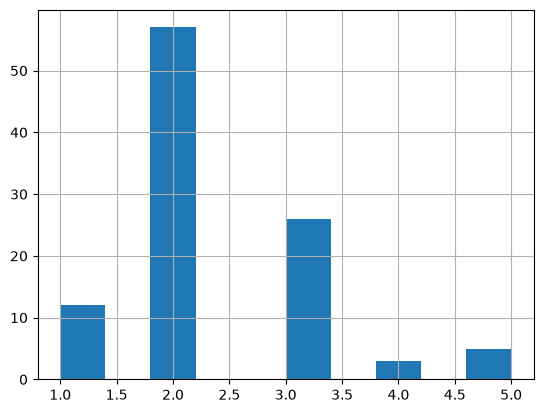

In [905]:
df['ideal_location_visits'].hist()
df['ideal_location_visits'].value_counts().sort_values()

In [906]:
df.drop(columns={'How many locations would you like to visit?'}, inplace=True)

<Axes: >

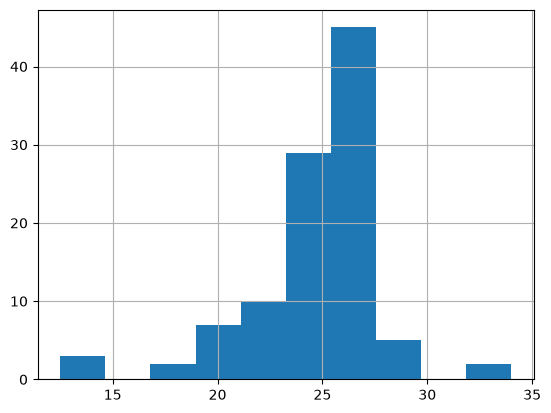

In [909]:
df.nightend.hist()

In [910]:
df.rename(columns={'nightend': 'nightend_hour'}, inplace = True)

In [911]:
df.nunique()

21?                             2
night_out_last30                2
under_influence                 2
age                            16
gender                          3
finance                         5
day_of_week                     7
plan_rating                     4
pregame                         2
transportation                  5
hours_out                      10
money_spent_usd                32
alcohol_consumed                2
nonAlcoholic_substance          2
sobriety_level_night            6
locations_or_venues_visited     6
y                               8
pregame_needed_q                2
money_needed_night_out         22
alcohol_needed_q                2
height_cm                      19
education_ranking               5
neighborhood                   26
survey_source_clean             6
start_hour                     30
start_hour_model               30
venue_clean                     7
group_size                      8
with_friends                    2
with_partner  

In [912]:
df.to_csv("cleaned_survey.csv", index=False)

print("Saved successfully!")
print("Shape:", df.shape)

Saved successfully!
Shape: (103, 48)


In [913]:
df[['transportation', 'transport_clean']]

,transportation,transport_clean
2,Ride-share / Taxi,Rideshare
3,Ride-share / Taxi,Walking
4,Riding with someone else,Passenger
5,Ride-share / Taxi,Passenger
6,Driving myself,Driving
...,...,...
102,Public transportation,Public Transit
103,Public transportation,Driving
104,Public transportation,Public Transit
105,Public transportation,Public Transit


In [914]:
df[['sobriety_level_night', 'sobriety_clean']]

,sobriety_level_night,sobriety_clean
2,Tipsy,Tipsy
3,Drunk,Drunk
4,Sober,Sober
5,Sober,Sober
6,Tipsy,Tipsy
...,...,...
102,Sober,Sober
103,Sober,Sober
104,Sober,Sober
105,Sober,Sober


In [917]:
df['sobriety_level_night'] == df.sobriety_clean

2      True
3      True
4      True
5      True
6      True
       ... 
102    True
103    True
104    True
105    True
106    True
Length: 103, dtype: bool

In [918]:
transport_map = {
    "Ride-share / Taxi": "Rideshare",
    "Walking": "Walking",
    "Riding with someone else": "Passenger",
    "Driving myself": "Driving",
    "Public transportation": "Public Transit",
    "Bicycle / Other": "Bicycle / Other"
}

df["transport_clean"] = df["transportation"].map(transport_map)

# Verify
print(pd.crosstab(df["transportation"], df["transport_clean"]))
print("Unmatched:", df["transport_clean"].isna().sum())

transport_clean           Driving  Passenger  Public Transit  Rideshare  \
transportation                                                            
Driving myself                 11          0               0          0   
Public transportation           0          0              27          0   
Ride-share / Taxi               0          0               0         33   
Riding with someone else        0         13               0          0   
Walking                         0          0               0          0   

transport_clean           Walking  
transportation                     
Driving myself                  0  
Public transportation           0  
Ride-share / Taxi               0  
Riding with someone else        0  
Walking                        19  
Unmatched: 0


In [920]:
df.loc[
    df["sobriety_level_night"] == "Tispy and Non-Sober",
    "sobriety_clean"
] = "Tipsy"

In [921]:
pd.crosstab(
    df["sobriety_level_night"],
    df["sobriety_clean"],
    dropna=False
)

sobriety_clean,Drunk,Sober,Tipsy,Unspecified intoxication
sobriety_level_night,,,,
Drunk,19,0,0,0
Drunk and Non-Sober,11,0,0,0
Non-Sober,0,0,0,4
Sober,0,40,0,0
Tipsy,0,0,20,0
Tispy and Non-Sober,0,0,9,0


In [922]:
df.drop(columns=[
    'sobriety_level_night',
    'transportation',
    'start_hour',
    'nightend_hour'
], inplace=True)

In [923]:
df.to_csv("model_clean.csv", index=False)

In [924]:
df=pd.read_csv("model_clean.csv")

In [925]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Load your cleaned survey
df = pd.read_csv("model_clean.csv")

# Set target and predictors
y = df["y"]
X = df.drop(columns=["y"])

# Convert categorical predictors into dummy variables
X = pd.get_dummies(X, drop_first=True, dtype=float)

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Inspect missing values
print("Missing values:")
print(X.isna().sum()[X.isna().sum() > 0])

# Temporary solution: fill missing numeric predictors with medians
X = X.fillna(X.median())

# Add intercept
X_ols = sm.add_constant(X)

# Fit OLS
model = sm.OLS(y, X_ols).fit()

print(model.summary())

Missing values:
height_cm    19
dtype: int64
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.340
Method:                 Least Squares   F-statistic:                     1.577
Date:                Mon, 23 Nov 2026   Prob (F-statistic):              0.205
Time:                        14:09:27   Log-Likelihood:                -64.064
No. Observations:                 103   AIC:                             312.1
Df Residuals:                      11   BIC:                             554.5
Df Model:                          91                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

/var/folders/cx/qk1b249j0fs0kqqcml92l_t40000gn/T/ipykernel_99802/503069915.py:29: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y, X_ols).fit()


In [926]:
print("Observations:", X.shape[0])
print("Predictors:", X.shape[1])
print("Matrix rank:", np.linalg.matrix_rank(X_ols))

Observations: 103
Predictors: 93
Matrix rank: 92


In [927]:
df.corr(numeric_only=True)

,age,finance,plan_rating,hours_out,money_spent_usd,locations_or_venues_visited,y,money_needed_night_out,height_cm,education_ranking,...,with_alone,ate_nothing,ate_at_home,ate_delivery,ate_restaurant,night_end_hour_model,ideal_group_size,substance_Maybe,substance_Yes,ideal_location_visits
age,1.000000,-0.020291,0.067683,0.003208,0.168770,-0.045049,0.117793,0.172785,0.015287,0.492886,...,-0.105426,-0.131886,-0.027814,0.017128,0.143979,-0.109547,0.045474,0.058237,-0.057817,-0.087492
finance,-0.020291,1.000000,-0.075889,0.039154,0.121958,-0.000546,0.266882,0.168641,-0.093196,0.173840,...,0.009193,-0.083764,-0.117498,0.152084,0.066097,-0.047625,-0.107674,-0.159393,0.010134,0.062859
plan_rating,0.067683,-0.075889,1.000000,0.058451,0.004258,-0.081337,-0.032784,-0.099256,-0.086931,0.080670,...,-0.080434,0.143675,0.093961,-0.177252,-0.081569,-0.121260,0.131651,0.045194,-0.075819,-0.055514
hours_out,0.003208,0.039154,0.058451,1.000000,0.255666,0.319579,0.246433,0.064307,-0.001115,0.124080,...,0.184177,-0.209483,0.106060,0.157211,-0.028533,0.156974,0.119035,-0.001652,0.225703,0.138860
money_spent_usd,0.168770,0.121958,0.004258,0.255666,1.000000,0.255131,0.063406,0.529715,0.183066,0.301287,...,0.085839,-0.073660,-0.072444,0.105703,0.052474,0.063590,0.042409,0.185640,0.208856,0.111149
locations_or_venues_visited,-0.045049,-0.000546,-0.081337,0.319579,0.255131,1.000000,0.087143,0.069732,0.142270,0.039724,...,0.118192,0.016312,-0.147564,0.078734,0.058316,0.188687,-0.010655,0.029947,0.116811,0.482699
y,0.117793,0.266882,-0.032784,0.246433,0.063406,0.087143,1.000000,0.099765,-0.055325,0.240333,...,0.004622,-0.087850,0.000128,0.070214,0.027174,-0.027836,0.032850,-0.054020,0.043356,0.187874
money_needed_night_out,0.172785,0.168641,-0.099256,0.064307,0.529715,0.069732,0.099765,1.000000,0.006349,0.204084,...,0.074513,-0.071686,-0.176179,0.260719,0.017012,0.106630,0.040668,-0.029778,0.275746,0.273887
height_cm,0.015287,-0.093196,-0.086931,-0.001115,0.183066,0.142270,-0.055325,0.006349,1.000000,-0.143402,...,0.135566,0.078111,0.034564,0.094137,-0.193411,-0.014703,0.060833,-0.074163,0.062287,0.121311
education_ranking,0.492886,0.173840,0.080670,0.124080,0.301287,0.039724,0.240333,0.204084,-0.143402,1.000000,...,0.007164,-0.079573,-0.073054,0.161346,0.010991,0.083328,0.207113,0.198314,0.243518,0.098505


In [940]:
name = "model_clean.csv" # fill in the blank
df = pd.read_csv(name)

if('Timestamp' in df.columns):
    df = df.drop(columns=['Timestamp']) # drop timestamp column if it exists




df = pd.get_dummies(df, drop_first=True, dtype=float) # convert categorical variables to dummy variables
#perform OLS
X = df.drop(columns=['y']) # Independent variables
y = df['y'] # target


X = X.fillna(X.median())
X = X.drop(columns=["ate_nothing"])
X = X.drop(columns=["survey_source_clean_Work"])
X = sm.add_constant(X) # our intercept (beta_0)


import numpy as np

print("Observations:", X.shape[0])
print("Columns:", X.shape[1])
print("Rank:", np.linalg.matrix_rank(X.to_numpy()))

# Find columns that contain only one unique value
constant_cols = X.columns[X.nunique(dropna=False) == 1]
print("\nConstant columns:", constant_cols.tolist())

# Find exact duplicate columns
duplicates = X.T.duplicated()
print("\nDuplicate columns:", X.columns[duplicates].tolist())

model = sm.OLS(y, X).fit() # Fit OLS regression

print("OLS Regression Results:") # OLS Regression Results
print(model.summary())

Observations: 103
Columns: 92
Rank: 92

Constant columns: ['const']

Duplicate columns: []
OLS Regression Results:
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.340
Method:                 Least Squares   F-statistic:                     1.577
Date:                Tue, 24 Nov 2026   Prob (F-statistic):              0.205
Time:                        13:19:35   Log-Likelihood:                -64.064
No. Observations:                 103   AIC:                             312.1
Df Residuals:                      11   BIC:                             554.5
Df Model:                          91                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025

<Axes: >

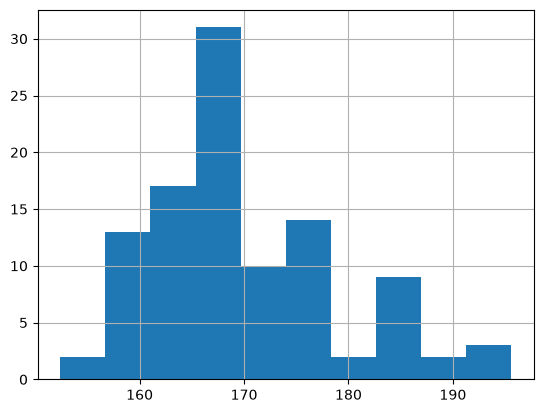

In [933]:
X.height_cm.hist()

In [935]:
df.height_cm.median()

np.float64(167.64)

In [936]:
X.height_cm.median()

np.float64(167.64)

<Axes: >

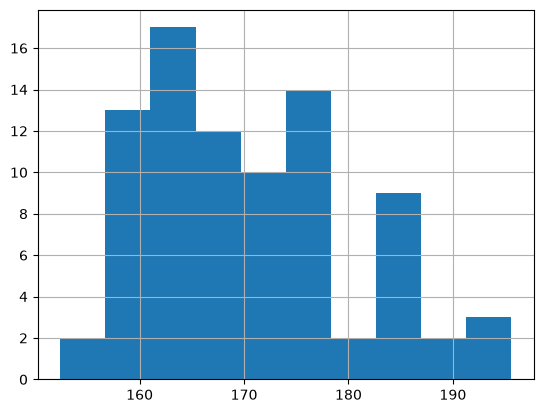

In [934]:
df.height_cm.hist()

In [944]:
df.survey_source_clean_Work.unique()

array([0., 1.])

In [945]:
df.drop(columns={'ate_nothing', 'survey_source_clean_Work'}, inplace = True)

In [947]:
df.to_csv("model_full_rank.csv", index=False)

In [959]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import statsmodels.api as sm


from sklearn.linear_model import LassoCV, RidgeCV, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
X = df.drop(columns=['y']) # Independent variables
X = X.fillna(X.median())
y = df['y'] # target

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 2026) # train/split
scaler = StandardScaler() # scale data
X_train = scaler.fit_transform(X_train) # fit transform train data
X_test = scaler.transform(X_test) # transform test data


model = LassoCV(cv=5, random_state=2026) # create Lasso model, splits into 5 cross validation folds to find the best alpha
model.fit(X_train, y_train) # fit model
y_pred = model.predict(X_test) # predict test data

#results
print("Best alpha:", model.alpha_)
print("Lasso Regression Results:") # Lasso Regression Results
print("Mean Squared Error:", mean_squared_error(y_test, y_pred)) # Mean Squ
print("R-squared:", r2_score(y_test, y_pred)) # R-squared
print("Coefficients:", model.coef_) # Coefficients
print("Intercept:", model.intercept_) # Intercept

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.928519e-02, tolerance: 1.882e-02
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.024754e-02, tolerance: 1.882e-02
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.835930e-

Best alpha: 0.12677541037041734
Lasso Regression Results:
Mean Squared Error: 2.1332317371628227
R-squared: -0.15006747688117938
Coefficients: [ 0.          0.48738416 -0.05464168  0.28364662  0.          0.
  0.         -0.          0.00059233  0.         -0.1094729  -0.
 -0.04584987 -0.          0.04320902  0.          0.         -0.
  0.10326379 -0.          0.         -0.         -0.          0.
  0.15566143  0.         -0.          0.09164631 -0.         -0.
  0.0279741  -0.1009967   0.          0.          0.07765433  0.1698912
 -0.         -0.         -0.         -0.18606178 -0.         -0.40738267
  0.1255508   0.          0.         -0.          0.         -0.
 -0.          0.         -0.          0.         -0.02535563 -0.
  0.         -0.          0.          0.         -0.26193558 -0.20339675
  0.0895929   0.          0.          0.03016731 -0.11238575  0.
 -0.         -0.          0.         -0.00551429  0.00478879 -0.
  0.          0.         -0.          0.         -0.  

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.748976e-02, tolerance: 2.021e-02
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.241325e-02, tolerance: 2.021e-02
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.036985e-

In [960]:
df.isna().sum().sum()

np.int64(19)

In [925]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Load your cleaned survey
df = pd.read_csv("model_clean.csv")

# Set target and predictors
y = df["y"]
X = df.drop(columns=["y"])

# Convert categorical predictors into dummy variables
X = pd.get_dummies(X, drop_first=True, dtype=float)

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Inspect missing values
print("Missing values:")
print(X.isna().sum()[X.isna().sum() > 0])

# Temporary solution: fill missing numeric predictors with medians
X = X.fillna(X.median())

# Add intercept
X_ols = sm.add_constant(X)

# Fit OLS
model = sm.OLS(y, X_ols).fit()

print(model.summary())

Missing values:
height_cm    19
dtype: int64
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.340
Method:                 Least Squares   F-statistic:                     1.577
Date:                Mon, 23 Nov 2026   Prob (F-statistic):              0.205
Time:                        14:09:27   Log-Likelihood:                -64.064
No. Observations:                 103   AIC:                             312.1
Df Residuals:                      11   BIC:                             554.5
Df Model:                          91                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

/var/folders/cx/qk1b249j0fs0kqqcml92l_t40000gn/T/ipykernel_99802/503069915.py:29: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y, X_ols).fit()


In [962]:
#pd.set_option()
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
df.nunique()

age                                        16
finance                                     5
plan_rating                                 4
hours_out                                  10
money_spent_usd                            32
locations_or_venues_visited                 6
y                                           8
money_needed_night_out                     22
height_cm                                  19
education_ranking                           5
start_hour_model                           30
group_size                                  8
with_friends                                2
with_partner                                2
with_family                                 2
with_coworkers                              2
with_mixed_other                            2
with_alone                                  2
ate_at_home                                 2
ate_delivery                                2
ate_restaurant                              2
night_end_hour_model              

In [963]:
df.isna().sum()

age                                         0
finance                                     0
plan_rating                                 0
hours_out                                   0
money_spent_usd                             0
locations_or_venues_visited                 0
y                                           0
money_needed_night_out                      0
height_cm                                  19
education_ranking                           0
start_hour_model                            0
group_size                                  0
with_friends                                0
with_partner                                0
with_family                                 0
with_coworkers                              0
with_mixed_other                            0
with_alone                                  0
ate_at_home                                 0
ate_delivery                                0
ate_restaurant                              0
night_end_hour_model              

In [964]:
df.median()

age                                         21.00
finance                                      3.00
plan_rating                                  3.00
hours_out                                    5.00
money_spent_usd                             35.00
locations_or_venues_visited                  2.00
y                                            8.00
money_needed_night_out                      50.00
height_cm                                  167.64
education_ranking                            2.00
start_hour_model                            20.50
group_size                                   5.00
with_friends                                 1.00
with_partner                                 0.00
with_family                                  0.00
with_coworkers                               0.00
with_mixed_other                             0.00
with_alone                                   0.00
ate_at_home                                  0.00
ate_delivery                                 0.00


In [965]:
df.fillna(df.median())

,age,finance,plan_rating,hours_out,money_spent_usd,locations_or_venues_visited,y,money_needed_night_out,height_cm,education_ranking,start_hour_model,group_size,with_friends,with_partner,with_family,with_coworkers,with_mixed_other,with_alone,ate_at_home,ate_delivery,ate_restaurant,night_end_hour_model,ideal_group_size,substance_Maybe,substance_Yes,ideal_location_visits,21?_Yes,night_out_last30_Yes,under_influence_Yes,gender_Male,gender_Non-Binary,day_of_week_Monday,day_of_week_Saturday,day_of_week_Sunday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday,pregame_Yes,alcohol_consumed_Yes,nonAlcoholic_substance_Yes,pregame_needed_q_Yes,alcohol_needed_q_Yes,neighborhood_Balboa,neighborhood_Bayview,neighborhood_Excelsior,neighborhood_Fillmore,neighborhood_Forest Hill,neighborhood_Golden Gate,neighborhood_Ingleside,neighborhood_Irving,neighborhood_Japantown,neighborhood_Laurel Heights,neighborhood_Lone Mountain,neighborhood_Lower Pacific Heights,neighborhood_Miraloma,neighborhood_Mission,neighborhood_Mission Bay,neighborhood_Outside SF,neighborhood_Panhandle,neighborhood_Parkmerced,neighborhood_Portola,neighborhood_Presidio,neighborhood_Richmond,neighborhood_SoMa,neighborhood_Sunset,neighborhood_USF Campus,neighborhood_Unknown,survey_source_clean_Personal Referral,survey_source_clean_Social Media,survey_source_clean_University,survey_source_clean_Unknown,venue_clean_Home,venue_clean_Other / Unknown,venue_clean_Other Venue,venue_clean_Outdoors / Public,venue_clean_Party / Event,venue_clean_Restaurant / Cafe,sobriety_clean_Sober,sobriety_clean_Tipsy,sobriety_clean_Unspecified intoxication,preferred_venue_Cafe,preferred_venue_Home,preferred_venue_Nightclub,preferred_venue_Other,preferred_venue_Restaurant,transport_clean_Passenger,transport_clean_Public Transit,transport_clean_Rideshare,transport_clean_Walking,sobriety_ideal_Sober,sobriety_ideal_Tipsy,sobriety_ideal_Unspecified Intoxication
0,21.0,4.0,3,5.0,150.0,3,3.0,50.0,180.34,2,20.000000,8,1,1,0,0,1,0,1,0,0,25.00,0,0,0,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,21.0,3.0,4,6.0,30.0,4,8.0,40.0,182.88,2,19.000000,8,1,0,1,0,0,0,1,0,0,27.00,6,0,0,3,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,22.0,2.0,4,5.0,10.0,2,8.0,15.0,167.64,2,17.000000,5,1,0,0,0,0,0,0,0,0,22.00,4,0,0,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,21.0,5.0,2,5.0,125.0,3,10.0,200.0,193.04,2,12.000000,1,0,0,0,0,0,1,0,1,0,26.00,2,0,0,5,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,22.0,4.0,1,3.0,100.0,3,6.0,100.0,164.00,2,23.333333,3,1,0,0,0,0,0,0,0,1,23.00,2,0,0,2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5,20.0,3.0,4,5.0,0.0,1,10.0,40.0,165.10,2,21.000000,4,1,0,0,0,1,0,1,0,0,25.00,4,0,1,2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,

In [966]:
df.isna().sum()

age                                         0
finance                                     0
plan_rating                                 0
hours_out                                   0
money_spent_usd                             0
locations_or_venues_visited                 0
y                                           0
money_needed_night_out                      0
height_cm                                  19
education_ranking                           0
start_hour_model                            0
group_size                                  0
with_friends                                0
with_partner                                0
with_family                                 0
with_coworkers                              0
with_mixed_other                            0
with_alone                                  0
ate_at_home                                 0
ate_delivery                                0
ate_restaurant                              0
night_end_hour_model              

In [969]:
df.fillna(df.median(), inplace= True)

In [970]:
df.isna().sum()

age                                        0
finance                                    0
plan_rating                                0
hours_out                                  0
money_spent_usd                            0
locations_or_venues_visited                0
y                                          0
money_needed_night_out                     0
height_cm                                  0
education_ranking                          0
start_hour_model                           0
group_size                                 0
with_friends                               0
with_partner                               0
with_family                                0
with_coworkers                             0
with_mixed_other                           0
with_alone                                 0
ate_at_home                                0
ate_delivery                               0
ate_restaurant                             0
night_end_hour_model                       0
ideal_grou

In [971]:
df.to_csv("model_filled.csv", index=False)

In [973]:
df.head()

,age,finance,plan_rating,hours_out,money_spent_usd,locations_or_venues_visited,y,money_needed_night_out,height_cm,education_ranking,start_hour_model,group_size,with_friends,with_partner,with_family,with_coworkers,with_mixed_other,with_alone,ate_at_home,ate_delivery,ate_restaurant,night_end_hour_model,ideal_group_size,substance_Maybe,substance_Yes,ideal_location_visits,21?_Yes,night_out_last30_Yes,under_influence_Yes,gender_Male,gender_Non-Binary,day_of_week_Monday,day_of_week_Saturday,day_of_week_Sunday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday,pregame_Yes,alcohol_consumed_Yes,nonAlcoholic_substance_Yes,pregame_needed_q_Yes,alcohol_needed_q_Yes,neighborhood_Balboa,neighborhood_Bayview,neighborhood_Excelsior,neighborhood_Fillmore,neighborhood_Forest Hill,neighborhood_Golden Gate,neighborhood_Ingleside,neighborhood_Irving,neighborhood_Japantown,neighborhood_Laurel Heights,neighborhood_Lone Mountain,neighborhood_Lower Pacific Heights,neighborhood_Miraloma,neighborhood_Mission,neighborhood_Mission Bay,neighborhood_Outside SF,neighborhood_Panhandle,neighborhood_Parkmerced,neighborhood_Portola,neighborhood_Presidio,neighborhood_Richmond,neighborhood_SoMa,neighborhood_Sunset,neighborhood_USF Campus,neighborhood_Unknown,survey_source_clean_Personal Referral,survey_source_clean_Social Media,survey_source_clean_University,survey_source_clean_Unknown,venue_clean_Home,venue_clean_Other / Unknown,venue_clean_Other Venue,venue_clean_Outdoors / Public,venue_clean_Party / Event,venue_clean_Restaurant / Cafe,sobriety_clean_Sober,sobriety_clean_Tipsy,sobriety_clean_Unspecified intoxication,preferred_venue_Cafe,preferred_venue_Home,preferred_venue_Nightclub,preferred_venue_Other,preferred_venue_Restaurant,transport_clean_Passenger,transport_clean_Public Transit,transport_clean_Rideshare,transport_clean_Walking,sobriety_ideal_Sober,sobriety_ideal_Tipsy,sobriety_ideal_Unspecified Intoxication
0,21.0,4.0,3,5.0,150.0,3,3.0,50.0,180.34,2,20.000000,8,1,1,0,0,1,0,1,0,0,25.0,0,0,0,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,21.0,3.0,4,6.0,30.0,4,8.0,40.0,182.88,2,19.000000,8,1,0,1,0,0,0,1,0,0,27.0,6,0,0,3,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,22.0,2.0,4,5.0,10.0,2,8.0,15.0,167.64,2,17.000000,5,1,0,0,0,0,0,0,0,0,22.0,4,0,0,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,21.0,5.0,2,5.0,125.0,3,10.0,200.0,193.04,2,12.000000,1,0,0,0,0,0,1,0,1,0,26.0,2,0,0,5,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,22.0,4.0,1,3.0,100.0,3,6.0,100.0,164.00,2,23.333333,3,1,0,0,0,0,0,0,0,1,23.0,2,0,0,2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [974]:
df = pd.get_dummies(df, drop_first=True, dtype=float) # convert categorical variables to dummy variables
#perform OLS
X = df.drop(columns=['y']) # Independent variables
y = df['y'] # target

X = sm.add_constant(X) # our intercept (beta_0)

model = sm.OLS(y, X).fit() # Fit OLS regression

print("OLS Regression Results:") # OLS Regression Results
print(model.summary())

OLS Regression Results:
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.340
Method:                 Least Squares   F-statistic:                     1.577
Date:                Wed, 25 Nov 2026   Prob (F-statistic):              0.205
Time:                        18:28:28   Log-Likelihood:                -64.064
No. Observations:                 103   AIC:                             312.1
Df Residuals:                      11   BIC:                             554.5
Df Model:                          91                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------

In [978]:
model

In [979]:
#perform Lasso
X = df.drop(columns=['y']) # Independent variables
y = df['y'] # target

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 2026) # train/split
scaler = StandardScaler() # scale data
X_train = scaler.fit_transform(X_train) # fit transform train data
X_test = scaler.transform(X_test) # transform test data


model = LassoCV(cv=5, random_state=2026) # create Lasso model, splits into 5 cross validation folds to find the best alpha
model.fit(X_train, y_train) # fit model
y_pred = model.predict(X_test) # predict test data

#results
print("Best alpha:", model.alpha_)
print("Lasso Regression Results:") # Lasso Regression Results
print("Mean Squared Error:", mean_squared_error(y_test, y_pred)) # Mean Squ
print("R-squared:", r2_score(y_test, y_pred)) # R-squared
print("Coefficients:", model.coef_) # Coefficients
print("Intercept:", model.intercept_) # Intercept

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.928519e-02, tolerance: 1.882e-02
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.024754e-02, tolerance: 1.882e-02
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.835930e-

Best alpha: 0.12677541037041734
Lasso Regression Results:
Mean Squared Error: 2.1332317371628227
R-squared: -0.15006747688117938
Coefficients: [ 0.          0.48738416 -0.05464168  0.28364662  0.          0.
  0.         -0.          0.00059233  0.         -0.1094729  -0.
 -0.04584987 -0.          0.04320902  0.          0.         -0.
  0.10326379 -0.          0.         -0.         -0.          0.
  0.15566143  0.         -0.          0.09164631 -0.         -0.
  0.0279741  -0.1009967   0.          0.          0.07765433  0.1698912
 -0.         -0.         -0.         -0.18606178 -0.         -0.40738267
  0.1255508   0.          0.         -0.          0.         -0.
 -0.          0.         -0.          0.         -0.02535563 -0.
  0.         -0.          0.          0.         -0.26193558 -0.20339675
  0.0895929   0.          0.          0.03016731 -0.11238575  0.
 -0.         -0.          0.         -0.00551429  0.00478879 -0.
  0.          0.         -0.          0.         -0.  

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.748976e-02, tolerance: 2.021e-02
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.241325e-02, tolerance: 2.021e-02
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.036985e-

In [981]:
df.shape

(103, 92)

In [982]:
#perform Ridge
X = df.drop(columns=['y']) # Independent variables
y = df['y'] # target

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 2026) # train/split
scaler = StandardScaler() # scale data
X_train = scaler.fit_transform(X_train) # fit transform train data
X_test = scaler.transform(X_test) # transform test data

model = RidgeCV(cv=5) # create Ridge model, splits into 5 cross validation folds to find the best alpha
model.fit(X_train, y_train) # fit model

#results


print("Ridge Regression Results:") # Ridge Regression Results
print("Best alpha:", model.alpha_)
print("Mean Squared Error:", mean_squared_error(y_test, model.predict(X_test))) # Mean Squared Error
print("R-squared:", r2_score(y_test, model.predict(X_test))) # R-squared
print("Coefficients:", model.coef_) # Coefficients

Ridge Regression Results:
Best alpha: 10.0
Mean Squared Error: 2.20488774484683
R-squared: -0.18869864972793615
Coefficients: [-0.08791491  0.62891935 -0.19971548  0.25635177 -0.0656605   0.02043084
 -0.12107845 -0.10564047  0.13144804 -0.14506204 -0.08072336 -0.10076734
 -0.12041078 -0.03736611  0.08665813  0.06988522  0.00735526  0.00864803
  0.39918911 -0.19064679  0.01981936  0.01547069 -0.12443586 -0.09713338
  0.21027391  0.00376651  0.05709511  0.23104341 -0.01277957 -0.14937338
  0.23143018 -0.20166333  0.          0.26685904  0.26709827  0.10917881
 -0.12879919  0.08866681 -0.02921731 -0.41457322 -0.19737922 -0.44522033
  0.32979147  0.         -0.13148281 -0.11428989 -0.07643212  0.02223167
 -0.04572133  0.08082665 -0.02819774 -0.01060308 -0.0895124  -0.01277741
  0.13453459 -0.19148691  0.18378919  0.13780486 -0.34465601 -0.32254305
  0.29842129  0.15772591 -0.0762321   0.12207292 -0.28393596  0.21273475
 -0.08451661 -0.04682713 -0.02969954 -0.35673112  0.35556525 -0.0795986

In [983]:
#perform Elastic Net
X = df.drop(columns=['y']) # Independent variables
y = df['y'] # target

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 2026) # train/split
scaler = StandardScaler() # scale data
X_train = scaler.fit_transform(X_train) # fit transform train data
X_test = scaler.transform(X_test) # transform test data

model = ElasticNet(alpha = 1, l1_ratio = 0.5, random_state=2026) # create Elastic Net model
model.fit(X_train, y_train) # fit model

y_pred = model.predict(X_test) # predict test data

#results
print("Elastic Net Regression Results:") # Elastic Net Regression Results
print("Mean Squared Error:", mean_squared_error(y_test, y_pred)) # Mean Squ
print("R-squared:", r2_score(y_test, y_pred)) # R-squared
print("Coefficients:", model.coef_) # Coefficients
print("Intercept:", model.intercept_) # Intercept


Elastic Net Regression Results:
Mean Squared Error: 1.8632431618321985
R-squared: -0.004511288958434667
Coefficients: [ 0.          0.00564793  0.          0.          0.          0.
  0.          0.          0.          0.         -0.          0.
 -0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
 -0.          0.          0.          0.          0.         -0.03286391
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.         -0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0. 